# SISPS-BATT-INT-CAL Oscilloscope

Oscilloscope measurements of the SISPS Battery Interposer for Lead Acid Battery Freezing Extent Measurement for verification of the impedance measurement method.

## Setup

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

from matplotlib.ticker import FuncFormatter, MultipleLocator
from matplotlib.figure import Figure
from matplotlib.axes import Axes
from matplotlib.lines import Line2D


from cycler import cycler

import re

import importlib

import scipy
from numpy.polynomial import Polynomial

from concurrent.futures import ThreadPoolExecutor

from typing import List, Tuple, Dict, Any

In [58]:
PLOT_OUTPUT_DIR = "../Plots"
os.makedirs(PLOT_OUTPUT_DIR, exist_ok=True)

In [59]:
# Clear anything to do with latex and reset matplotlib settings
import matplotlib

plt.close("all")
matplotlib.rcdefaults()

importlib.reload(matplotlib)
importlib.reload(plt)


plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)

In [60]:
# Add 4 more colors to the default color cycle for plotting
# Add four high-contrast colors that do not duplicate the default tab20 cycle
additional_colors = ["#000000", "#FFD700", "#00A6A6", "#E600A9"]

plt.rcParams["axes.prop_cycle"] = cycler(
    "color", plt.rcParams["axes.prop_cycle"].by_key()["color"] + additional_colors
)

## Data Import

In [61]:
SCOPE_DATA_PATH = "../Data/Oscilloscope/Data"
# SCOPE_IMG_PATH = "../Data/Oscilloscope/Images"

In [62]:
def find_scope_files(directory: str) -> List[str]:
    """
    Find all CSV files in the specified directory.

    Parameters:
        directory (str): The path to the directory to search for CSV files.

    Returns:
        List[str]: A list of file paths to the found CSV files.
    """
    return [
        os.path.join(directory, file)
        for file in os.listdir(directory)
        if file.endswith(".csv")
    ]


def load_scope_data(file_path: str) -> pd.DataFrame:
    """
    Load oscilloscope data from a CSV file.

    Parameters:
        file_path (str): The path to the CSV file containing the oscilloscope data.

    Returns:
        pd.DataFrame: A DataFrame containing the loaded oscilloscope data.
    """
    HEADER_ROWS = 68

    def dict_metadata(metadata_str: str) -> Dict[str, Any]:
        metadata = {}
        for line in metadata_str.splitlines():
            if "," in line:
                key, value = line.split(",")
                metadata[key.strip()] = value.strip()
        return metadata

    def get_metadata(name: str, header_lines: str) -> Dict[str, Any]:
        """
        Extract metadata for a specific channel from the header.
        Parameters:
            channel_num (int): The channel number to extract metadata for.
            header_lines (str): The header lines from the CSV file.

        Returns:
            Dict[str, Any]: A dictionary containing the extracted metadata.
        """
        params = re.search(
            rf"{name}\n(.*?)(?:\n\n|$)",
            header_lines,
            re.DOTALL,
        )
        if not params:
            raise ValueError(f"'{name}' metadata not found in header.")

        # Metadata is name,value pairs separated by a comma
        metadata = dict_metadata(params.group(1))
        return metadata

    print(f"Loading data from {file_path}...")

    df = pd.read_csv(file_path, skiprows=HEADER_ROWS)
    with open(file_path, "r") as f:
        header = "\n".join(f.read().splitlines()[:HEADER_ROWS])

    idMatch = re.match(r".*-T(\d\d)-C(\d\d).*\.csv", os.path.basename(file_path))
    if not idMatch:
        raise ValueError(f"Filename {file_path} does not match expected pattern.")

    df.attrs = {
        "Test": idMatch.group(1),
        "Battery": idMatch.group(2),
        "Channel 1": get_metadata("Channel 1", header),
        "Channel 2": get_metadata("Channel 2", header),
        "Channel 3": get_metadata("Channel 3", header),
        "Channel 4": get_metadata("Channel 4", header),
        "Math 1": get_metadata("Math 1", header),
        "Trigger": get_metadata("Trigger", header),
    }

    print(f"Loaded data for T{df.attrs['Test']}, C{df.attrs['Battery']}.")

    return df


scope_dfs = [load_scope_data(file) for file in find_scope_files(SCOPE_DATA_PATH)]
scope_dfs.sort(key=lambda df: int(df.attrs["Test"]))

Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T13-C13-EIS.csv...
Loaded data for T13, C13.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T09-C09-EIS.csv...
Loaded data for T09, C09.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T03-C03-EIS.csv...
Loaded data for T03, C03.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T10-C10-EIS.csv...
Loaded data for T10, C10.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T04-C04-EIS.csv...
Loaded data for T04, C04.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T14-C14-EIS.csv...
Loaded data for T14, C14.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T07-C07-EIS.csv...
Loaded data for T07, C07.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T12-C12-EIS.csv...
Loaded data for T12, C12.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T01-C01-EIS.csv...
Loaded data for T01, C01.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T08-C08-EIS.csv

In [63]:
EIS_DATA_FILE = "../Data/Stanton2025.csv"

eis_df = pd.read_csv(EIS_DATA_FILE)

## Phase Calculation

In [64]:
from tabulate import tabulate

PHASE_WINDOW = (0.1, 0.5)


def calculate_phase_difference(df: pd.DataFrame, window: Tuple[float, float]) -> float:
    TIME_MASK = (df["Time(s)"] >= window[0]) & (df["Time(s)"] <= window[1])
    TIME = df["Time(s)"][TIME_MASK]

    VOLTAGE = df["Channel2"][TIME_MASK]
    CURRENT = df["Channel1"][TIME_MASK]

    hanning_window = np.hanning(len(TIME))

    voltage = hanning_window * VOLTAGE
    current = hanning_window * CURRENT

    voltage_spectrum = np.fft.fft(voltage)
    current_spectrum = np.fft.fft(current)

    voltage_phase = np.angle(voltage_spectrum)
    current_phase = np.angle(current_spectrum)

    phase_diff = np.degrees(voltage_phase - current_phase)
    if phase_diff[1] < 0:
        phase_diff[1] += 360

    return phase_diff[1]


phase_differences = [calculate_phase_difference(df, PHASE_WINDOW) for df in scope_dfs]

# Print table
print(
    tabulate(
        [
            [df.attrs["Test"], df.attrs["Battery"], phase_diff]
            for df, phase_diff in zip(scope_dfs, phase_differences)
        ],
        headers=["Test", "Battery", "Phase Difference (degrees)"],
    )
)

  Test    Battery    Phase Difference (degrees)
------  ---------  ----------------------------
    01         01                       183.22
    02         02                       184.737
    03         03                       184.252
    04         04                       183.991
    05         05                       187.425
    06         06                       185.69
    07         07                       186.288
    08         08                       186.976
    09         09                       199.779
    10         10                       197.21
    11         11                       196.248
    12         12                       190.067
    13         13                       189.495
    14         14                       184.053


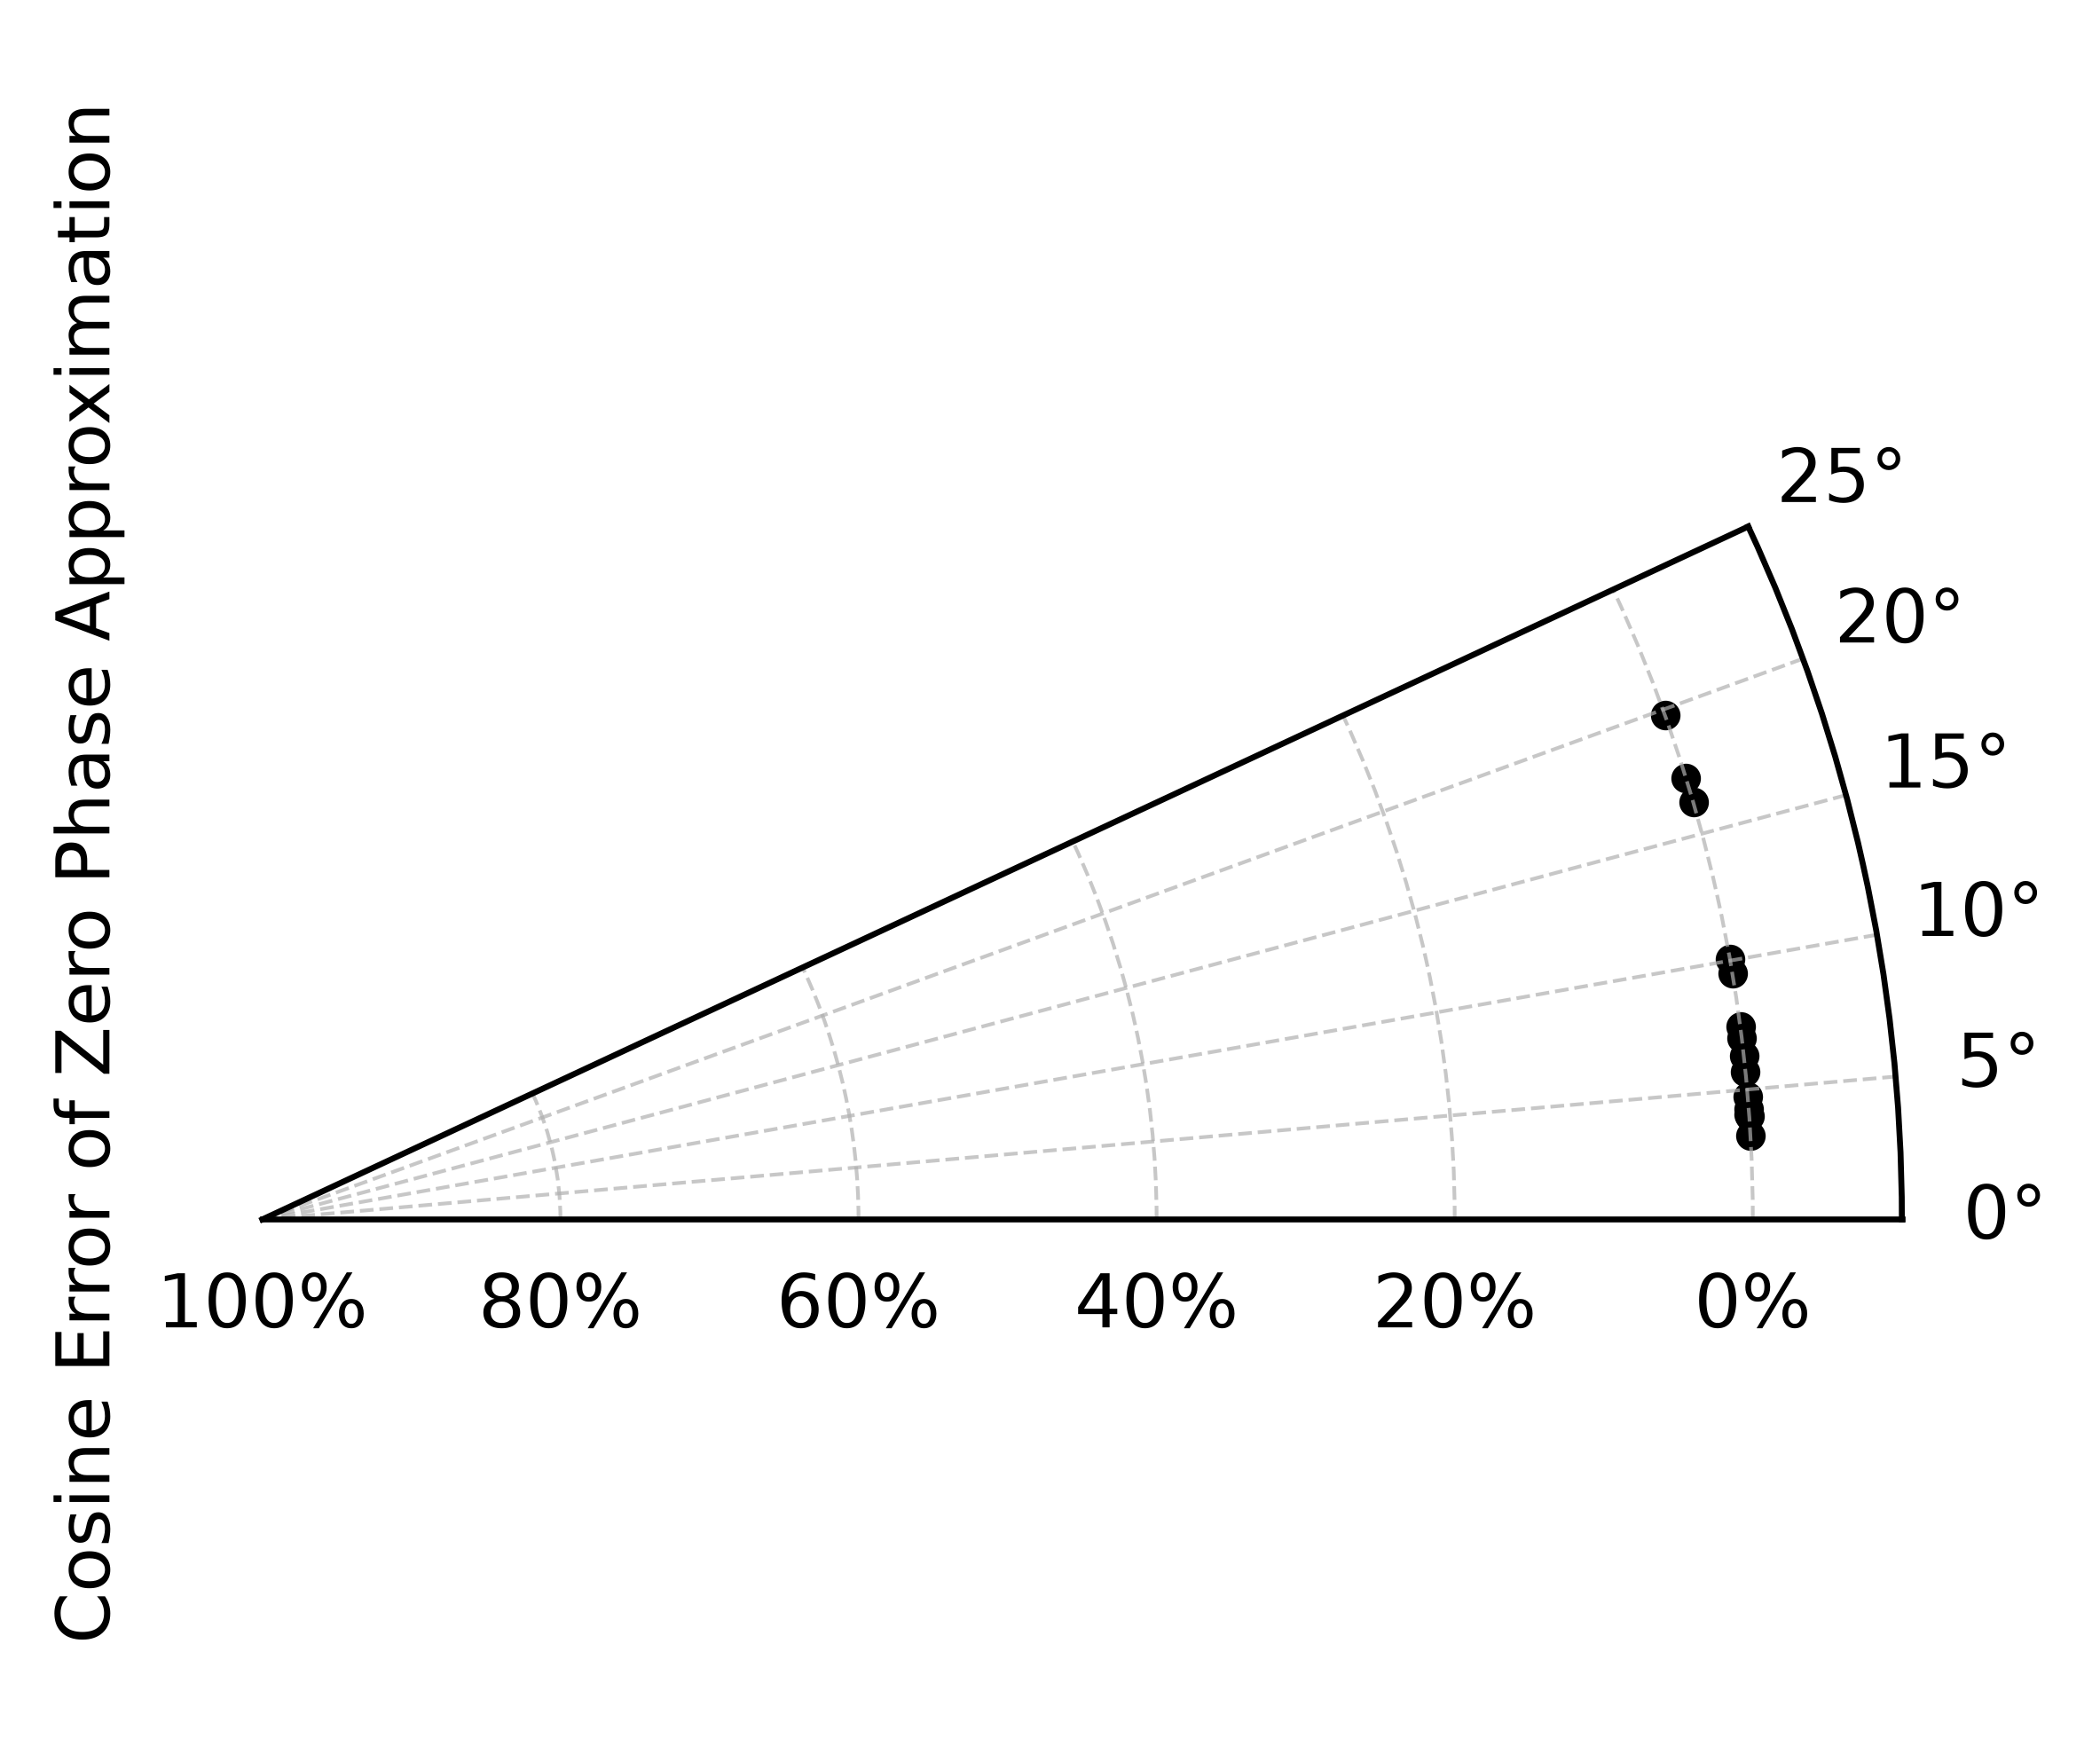

In [65]:
def plot_phase_differences(phase_differences: List[float]) -> Figure:
    """Plot phase differences on a unit polar circle."""
    fig, ax = plt.subplots(
        subplot_kw={"projection": "polar"},
        figsize=(4, 4),
    )

    angles = np.deg2rad(phase_differences) - np.pi
    ax.scatter(
        angles,
        np.ones(len(angles)),
        marker=".",
        color="black",
    )

    ax.set_ylim(0, 1.1)
    ax.set
    ax.set_thetamin(0)  # type: ignore
    ax.set_thetamax(25)  # type: ignore
    ax.grid(True, which="both", axis="both", linestyle="--", linewidth=0.5, alpha=0.7)

    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{(1 - y):.0%}"))
    ax.set_ylabel("Cosine Error of Zero Phase Approximation")

    ax.xaxis.set_major_locator(MultipleLocator(np.deg2rad(5)))

    return fig


plot_phase_differences(phase_differences)

## RMS Voltage, Current, Impedance Calculation

In [66]:
RMS_WINDOW = (0.1, 0.5)


def calculate_rms(
    series: pd.Series, time: pd.Series, window: Tuple[float, float]
) -> float:
    TIME_MASK = (time >= window[0]) & (time <= window[1])
    hanning_window = np.hanning(len(time[TIME_MASK]))
    signal = series[TIME_MASK] * hanning_window
    rms_value = np.sqrt(np.mean(signal**2)) * np.sqrt(
        8 / 3
    )  # Correcting for the RMS of a Hanning window

    return rms_value


CURRENT_GAIN = 5.5  # Current to voltage gain of the instrumentation amplifier
VOLTAGE_GAIN = 10.0  # Voltage gain (assumed to be 1 for direct measurement)

CURRENT_DIFF_P = 2.0  # Volts. Constant differential pair positive. Measured current is CURRENT_DIFF_N


def iamp_voltage_to_current(
    diff_n: pd.Series,
    DIFF_P: float = CURRENT_DIFF_P,
) -> pd.Series:
    current = (DIFF_P - diff_n) / CURRENT_GAIN
    return current


current_rms_values = [
    calculate_rms(
        iamp_voltage_to_current(diff_n=df["Channel1"]), df["Time(s)"], RMS_WINDOW
    )
    for df in scope_dfs
]
voltage_rms_values = [
    calculate_rms(df["Channel2"], df["Time(s)"], RMS_WINDOW) / VOLTAGE_GAIN
    for df in scope_dfs
]
scope_impedance_values = [
    voltage_rms / current_rms if current_rms > 0 else np.inf
    for voltage_rms, current_rms in zip(voltage_rms_values, current_rms_values)
]

for i in range(len(scope_dfs)):
    print(
        f"T{scope_dfs[i].attrs['Test']}, C{scope_dfs[i].attrs['Battery']}, Phase Difference: {phase_differences[i]:.2f}°, Voltage RMS: {1000*voltage_rms_values[i]:.3f} mV, Current RMS: {1000*current_rms_values[i]:.3f} mA, Impedance: {scope_impedance_values[i]:.6f} Ω"
    )

T01, C01, Phase Difference: 183.22°, Voltage RMS: 0.596 mV, Current RMS: 83.584 mA, Impedance: 0.007125 Ω
T02, C02, Phase Difference: 184.74°, Voltage RMS: 0.567 mV, Current RMS: 82.961 mA, Impedance: 0.006835 Ω
T03, C03, Phase Difference: 184.25°, Voltage RMS: 0.591 mV, Current RMS: 83.788 mA, Impedance: 0.007053 Ω
T04, C04, Phase Difference: 183.99°, Voltage RMS: 0.595 mV, Current RMS: 83.773 mA, Impedance: 0.007100 Ω
T05, C05, Phase Difference: 187.43°, Voltage RMS: 0.622 mV, Current RMS: 83.724 mA, Impedance: 0.007425 Ω
T06, C06, Phase Difference: 185.69°, Voltage RMS: 0.596 mV, Current RMS: 83.775 mA, Impedance: 0.007114 Ω
T07, C07, Phase Difference: 186.29°, Voltage RMS: 0.696 mV, Current RMS: 83.716 mA, Impedance: 0.008319 Ω
T08, C08, Phase Difference: 186.98°, Voltage RMS: 0.693 mV, Current RMS: 83.904 mA, Impedance: 0.008262 Ω
T09, C09, Phase Difference: 199.78°, Voltage RMS: 6.132 mV, Current RMS: 83.518 mA, Impedance: 0.073419 Ω
T10, C10, Phase Difference: 197.21°, Voltage R

In [67]:
import import_ipynb
from Impedance import freezing_extent, VBATT_DATA_PATH, load_vbatt_data  # type: ignore

In [68]:
# Print freezing extent data for each test
vbatt_data = load_vbatt_data(VBATT_DATA_PATH)

vbatt_dfs = []
for _, row in vbatt_data.iterrows():
    test_df = pd.DataFrame(
        {"freezing_extent": [freezing_extent(row["VBATT HT"] / 6, row["VBATT LT"] / 6)]}
    )
    vbatt_dfs.append(test_df)
for i, df in enumerate(vbatt_dfs):
    print(f"Test {i+1} freezing extent: {df['freezing_extent'].sum():.0%}")

Test 1 freezing extent: 0%
Test 2 freezing extent: 0%
Test 3 freezing extent: 0%
Test 4 freezing extent: 0%
Test 5 freezing extent: 0%
Test 6 freezing extent: 0%
Test 7 freezing extent: 8%
Test 8 freezing extent: 11%
Test 9 freezing extent: 16%
Test 10 freezing extent: 22%
Test 11 freezing extent: 29%
Test 12 freezing extent: 37%
Test 13 freezing extent: 43%
Test 14 freezing extent: 51%
Test 15 freezing extent: 10%
Test 16 freezing extent: 17%
Test 17 freezing extent: 17%
Test 18 freezing extent: 23%
Test 19 freezing extent: 44%
Test 20 freezing extent: 39%
Test 21 freezing extent: 48%
Test 22 freezing extent: 54%
Test 23 freezing extent: 59%
Test 24 freezing extent: 60%
Test 25 freezing extent: 62%
Test 26 freezing extent: 70%
Test 27 freezing extent: 75%
Test 28 freezing extent: 82%


In [69]:
vbatt = load_vbatt_data(VBATT_DATA_PATH).iloc[:14]

scope_freezing_extent_values: list[float] = [
    freezing_extent(vbatt_ht, vbatt_lt)
    for vbatt_ht, vbatt_lt in zip(vbatt["VBATT HT"] / 6, vbatt["VBATT LT"] / 6)
]

In [70]:
phase_differences_frozen = phase_differences[
    scope_freezing_extent_values.count(0.0) : len(phase_differences)
]
print(
    f"Mean Phase Difference (Frozen): {np.mean(phase_differences_frozen):.2f}°, Standard Deviation: {np.std(phase_differences_frozen):.2f}°"
)

Mean Phase Difference (Frozen): 191.26°, Standard Deviation: 5.39°


## Plotting

Archie's Law parameters: Z0 = 0.02, n = 5.60


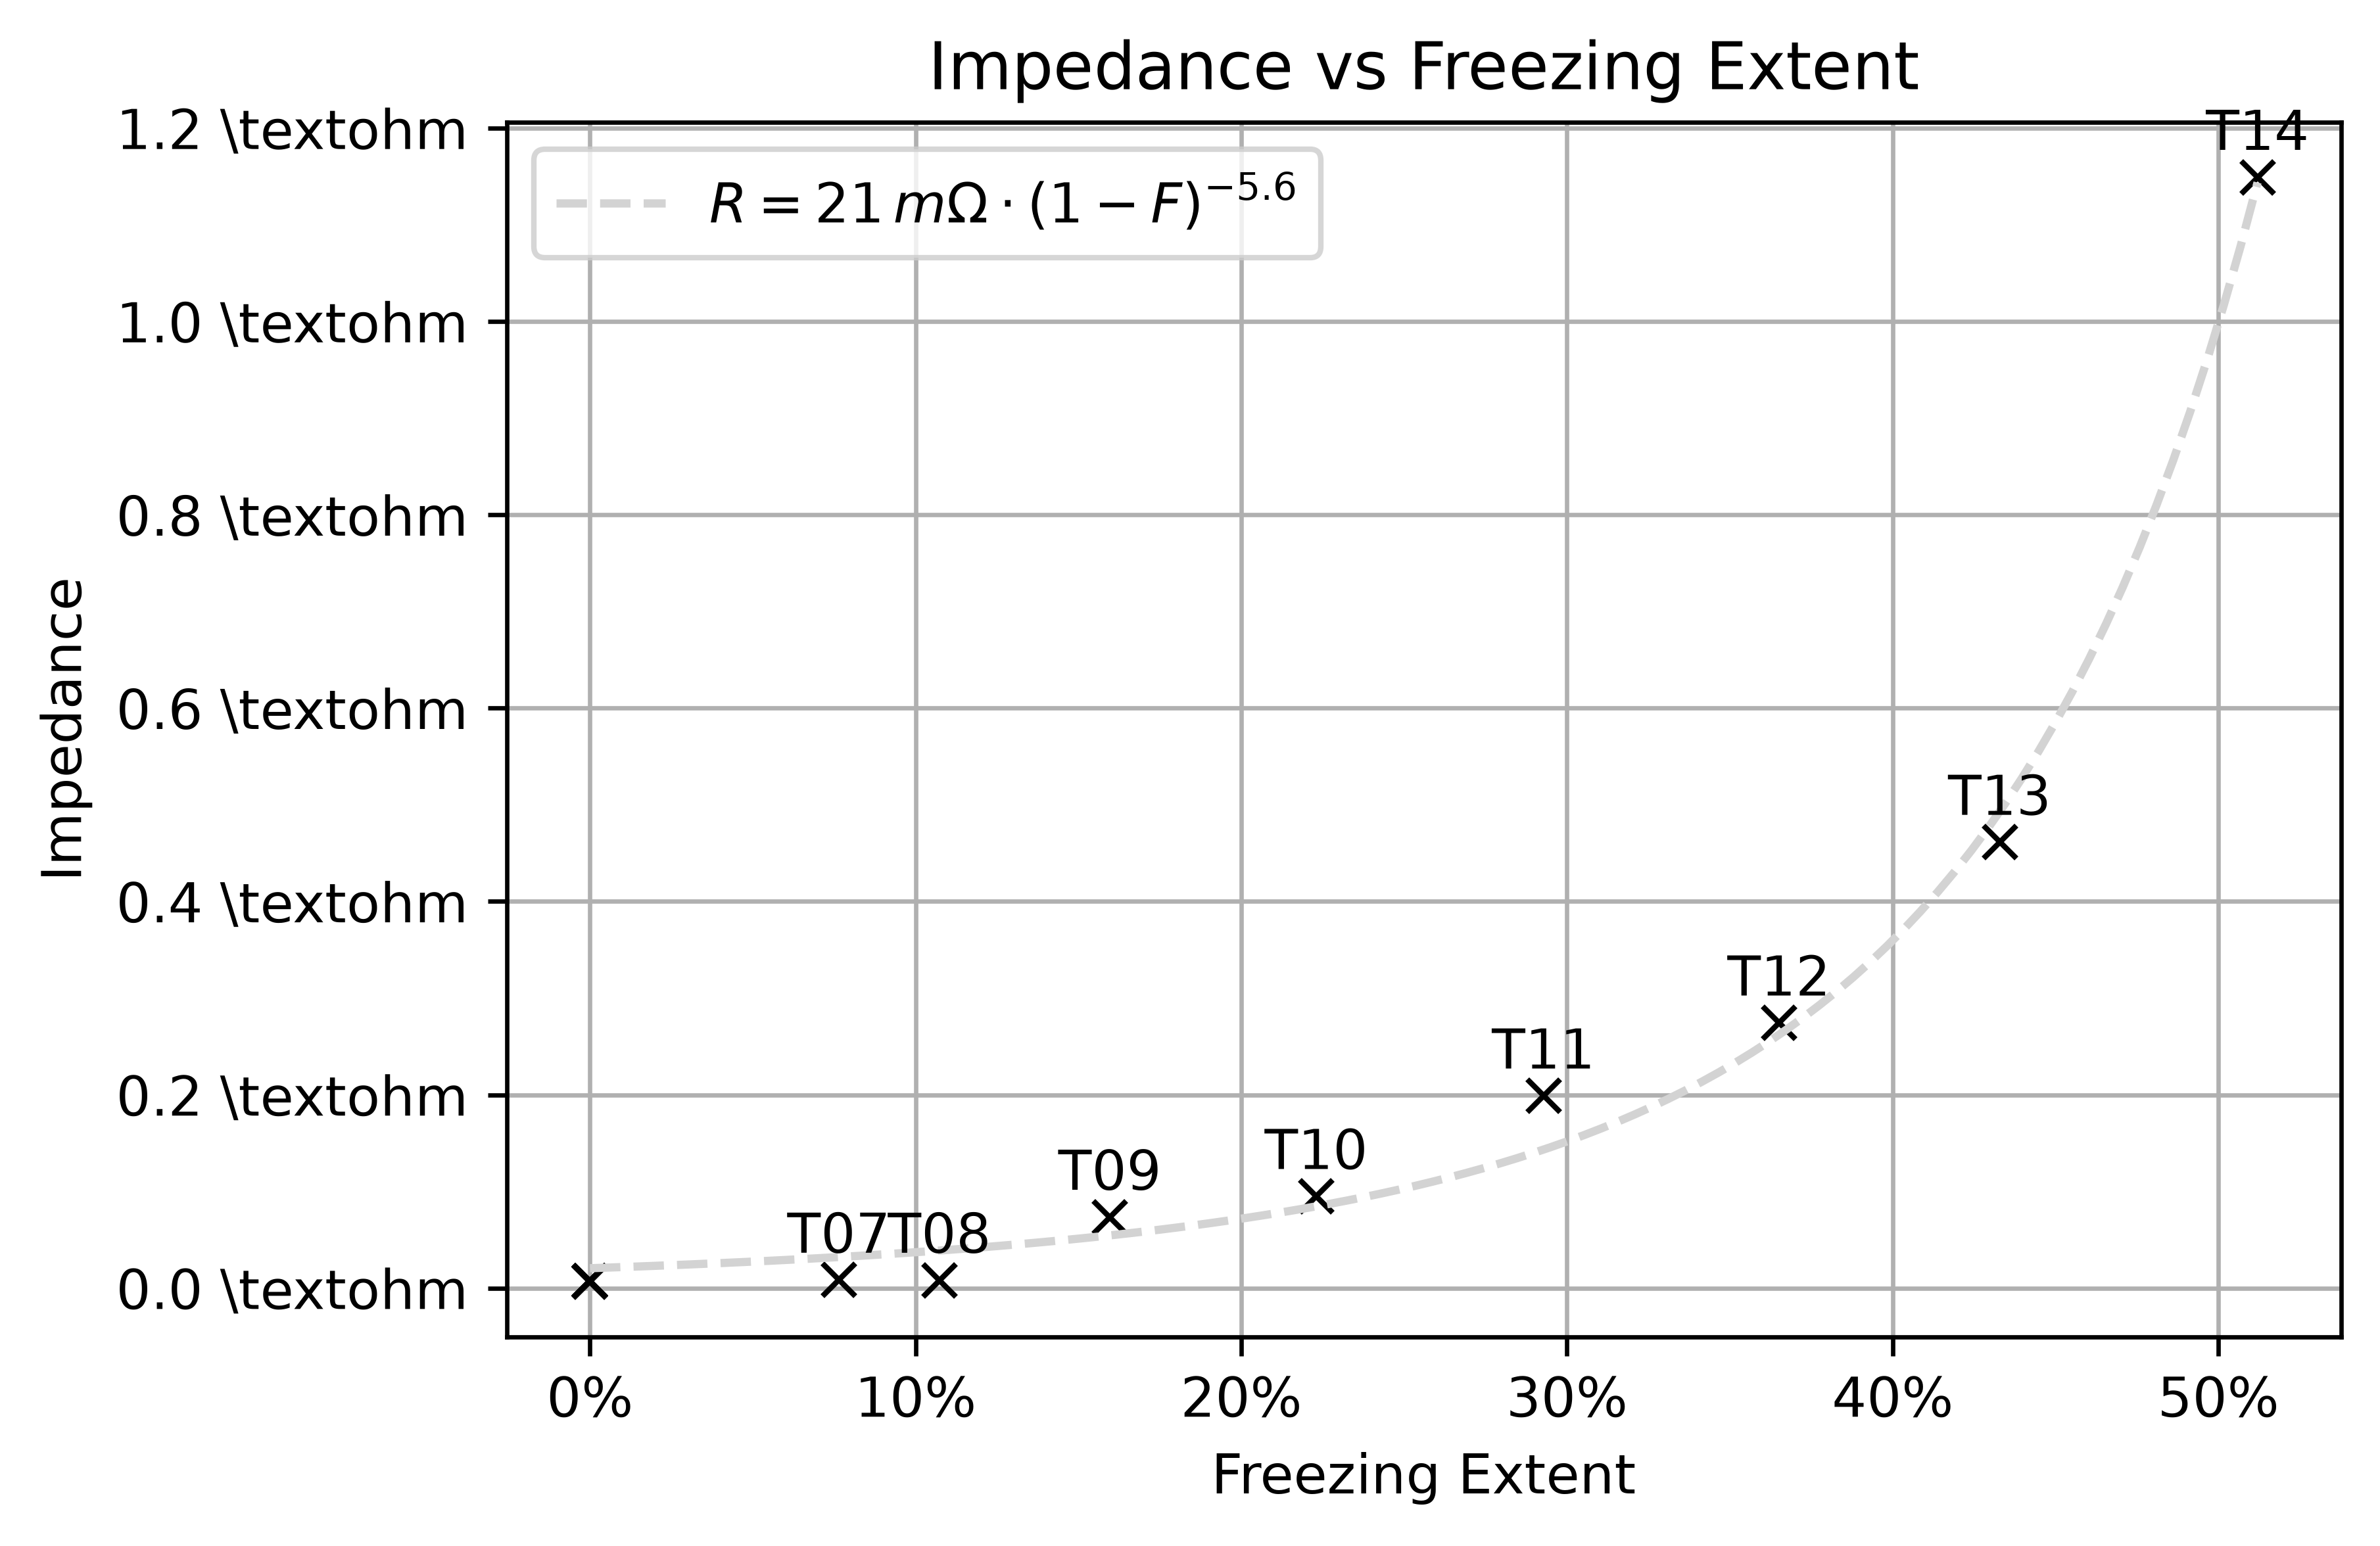

In [71]:
def plot_scope_impedance_vs_freezing_extent(
    impedance_values: List[float],
    freezing_extent_values: List[float],
) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(
        freezing_extent_values,
        impedance_values,
        marker="x",
        linestyle="",
        color="black",
    )

    for i in range(len(impedance_values)):
        if freezing_extent_values[i] == 0:
            continue
        ax.annotate(
            f"T{i+1:02d}",
            (freezing_extent_values[i], impedance_values[i]),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
        )

    # Fit data to Archie's Law: Z = Z0 * (1 - F)^(-n)
    popt, _ = scipy.optimize.curve_fit(
        lambda F, Z0, n: Z0 * (1 - F) ** (-n),
        freezing_extent_values,
        impedance_values,
        p0=(1.0, 1.0),
    )
    print(f"Archie's Law parameters: Z0 = {popt[0]:.2f}, n = {popt[1]:.2f}")

    F_fit = np.linspace(min(freezing_extent_values), max(freezing_extent_values), 100)
    Z_fit = popt[0] * (1 - F_fit) ** (-popt[1])
    ax.plot(
        F_fit,
        Z_fit,
        color="lightgray",
        linestyle="--",
        label=rf"$R = {1000*popt[0]:.0f}\,m\Omega \cdot (1 - F)^{{-{popt[1]:.1f}}}$",
    )

    ax.legend()

    ax.set_xlabel("Freezing Extent")
    ax.set_ylabel("Impedance")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: rf"{y:.1f} \textohm"))

    ax.set_title("Impedance vs Freezing Extent")
    ax.grid(True)
    return fig


plot_scope_impedance_vs_freezing_extent(
    scope_impedance_values, scope_freezing_extent_values
)

Archie's Law parameters: Z0 = 0.02, n = 5.60


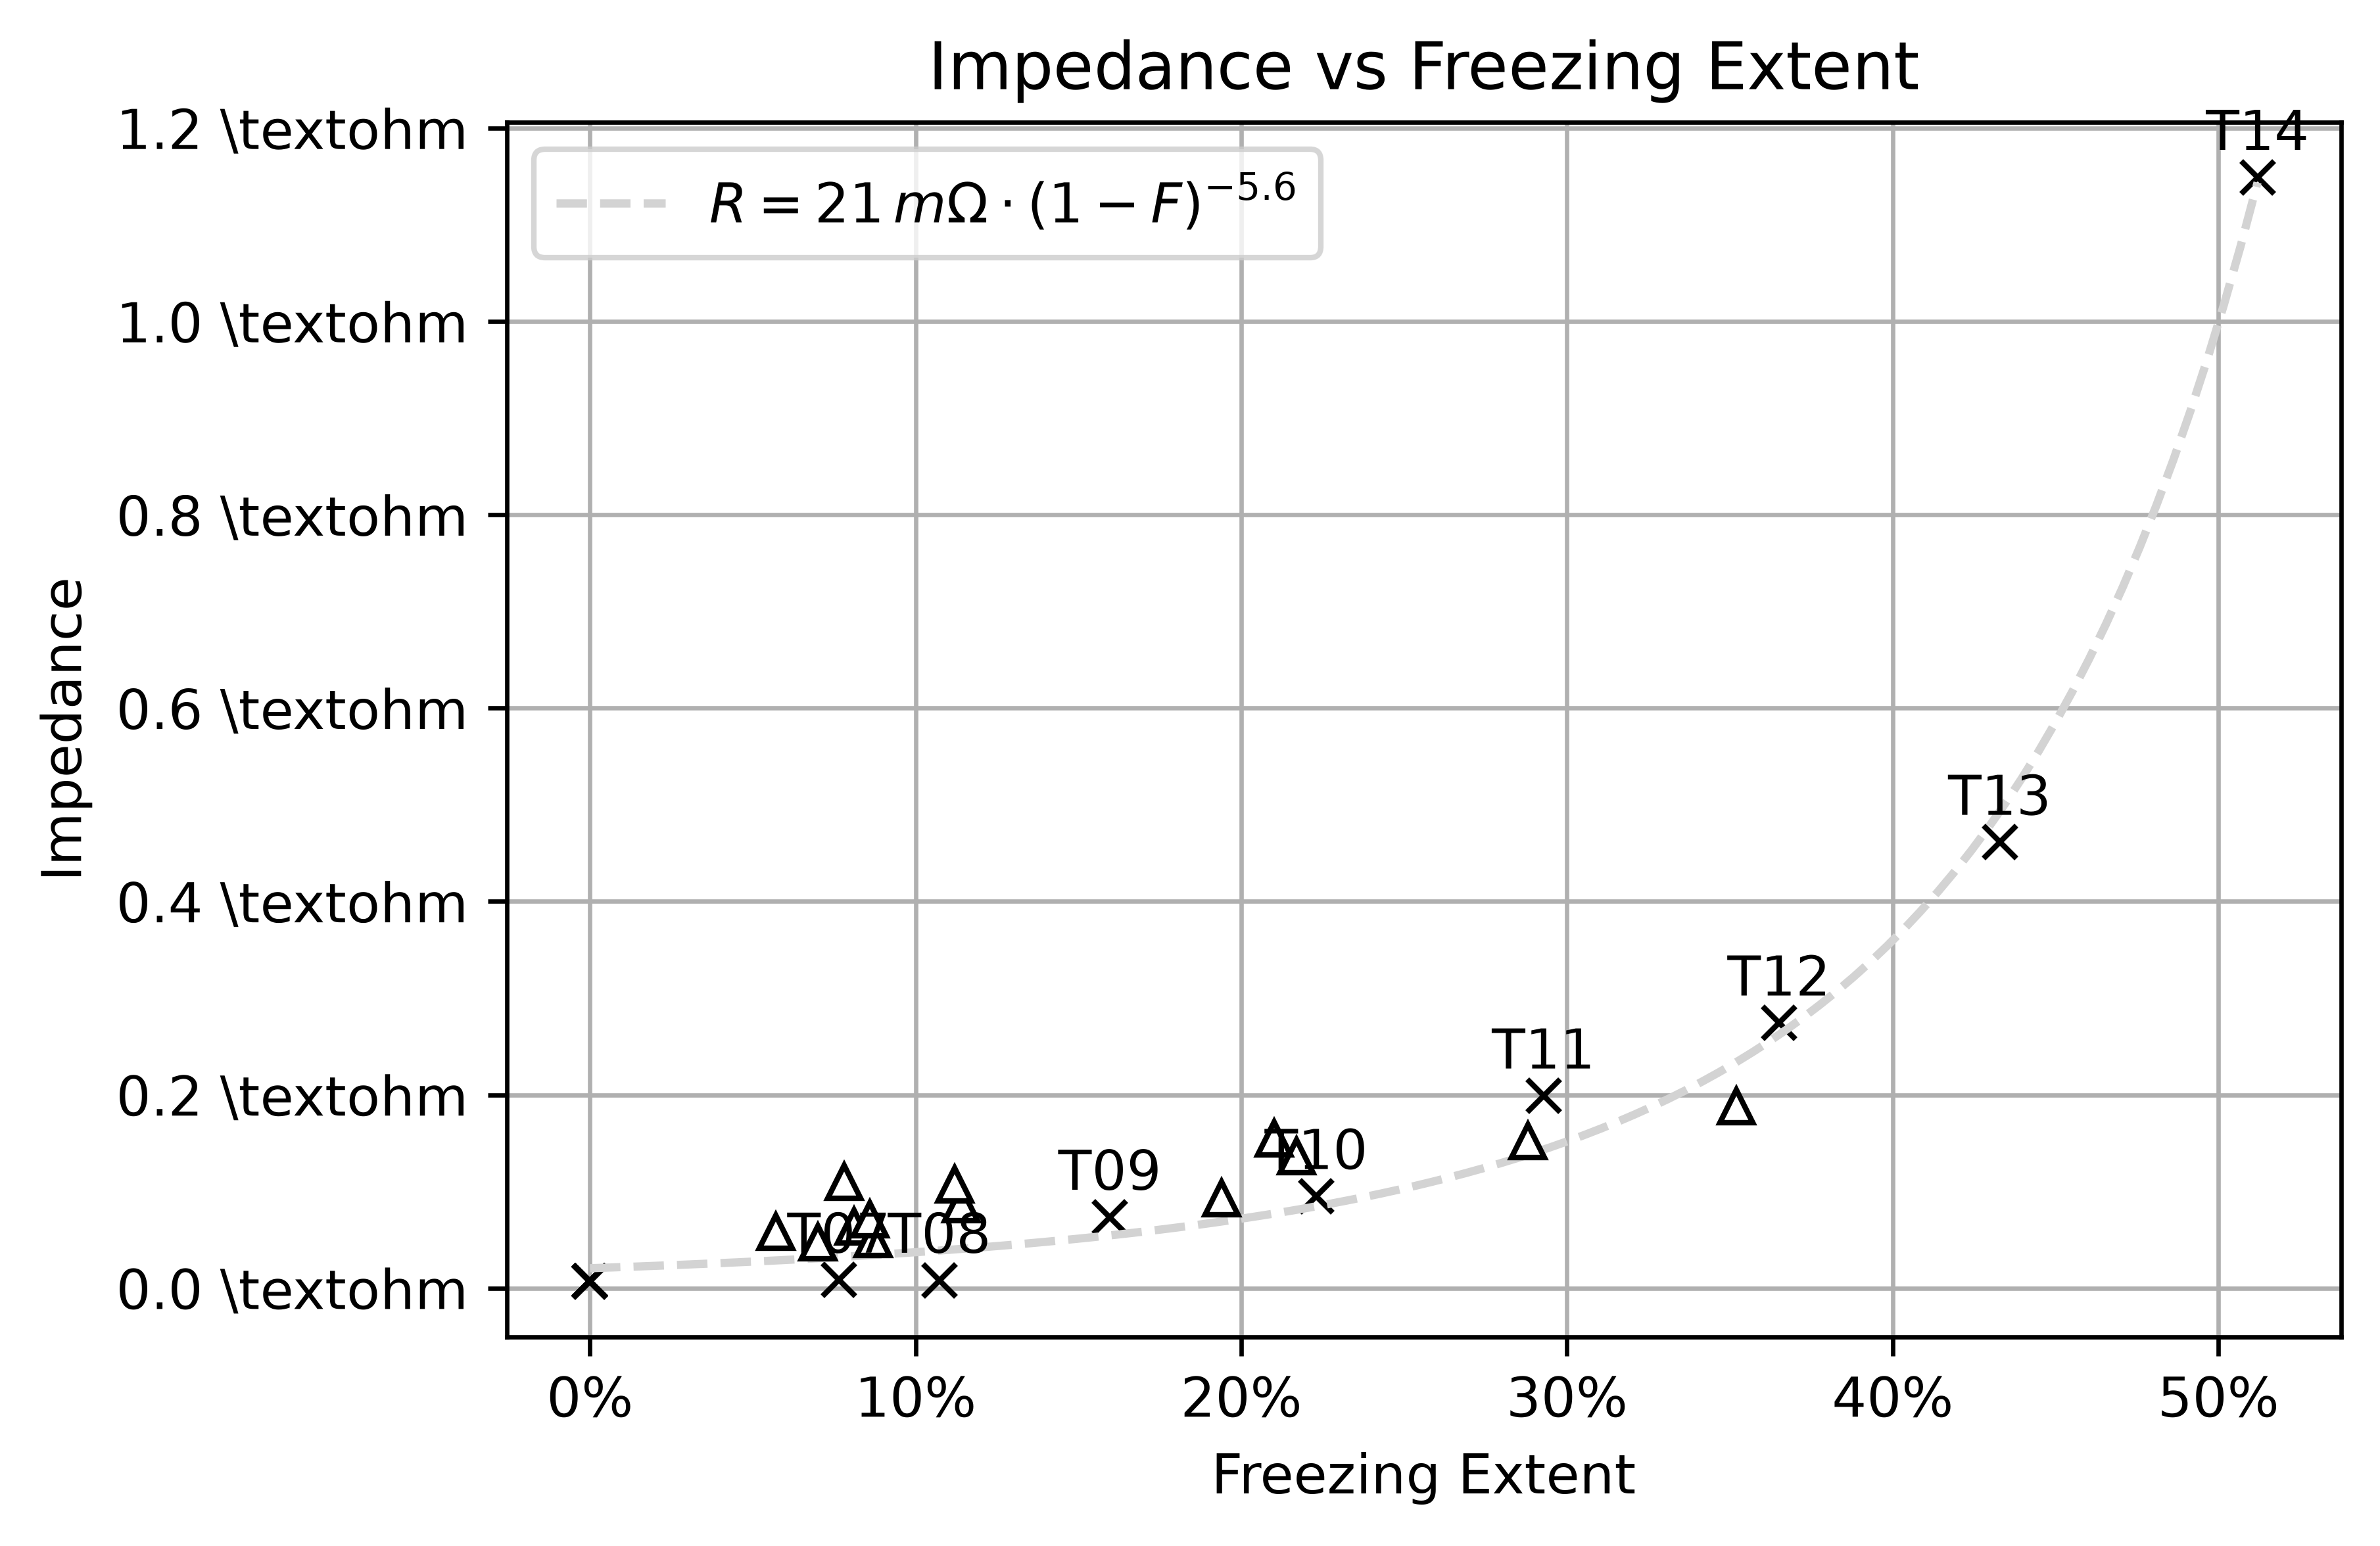

In [72]:
def add_eis_data_to_plot(
    ax: Axes, eis_data: pd.DataFrame, label: str = "EIS Data"
) -> Figure:
    ax.plot(
        eis_data["Freezing Extent"],
        eis_data["High Frequency Resistance(mOhm)"] / 1000,  # Convert mOhm to Ohm
        marker="^",
        linestyle="",
        markerfacecolor="white",
        markeredgecolor="black",
        label=label,
    )

    return ax.get_figure()


add_eis_data_to_plot(
    plot_scope_impedance_vs_freezing_extent(
        scope_impedance_values, scope_freezing_extent_values
    ).get_axes()[0],
    eis_df,
    label="EIS Data",
)

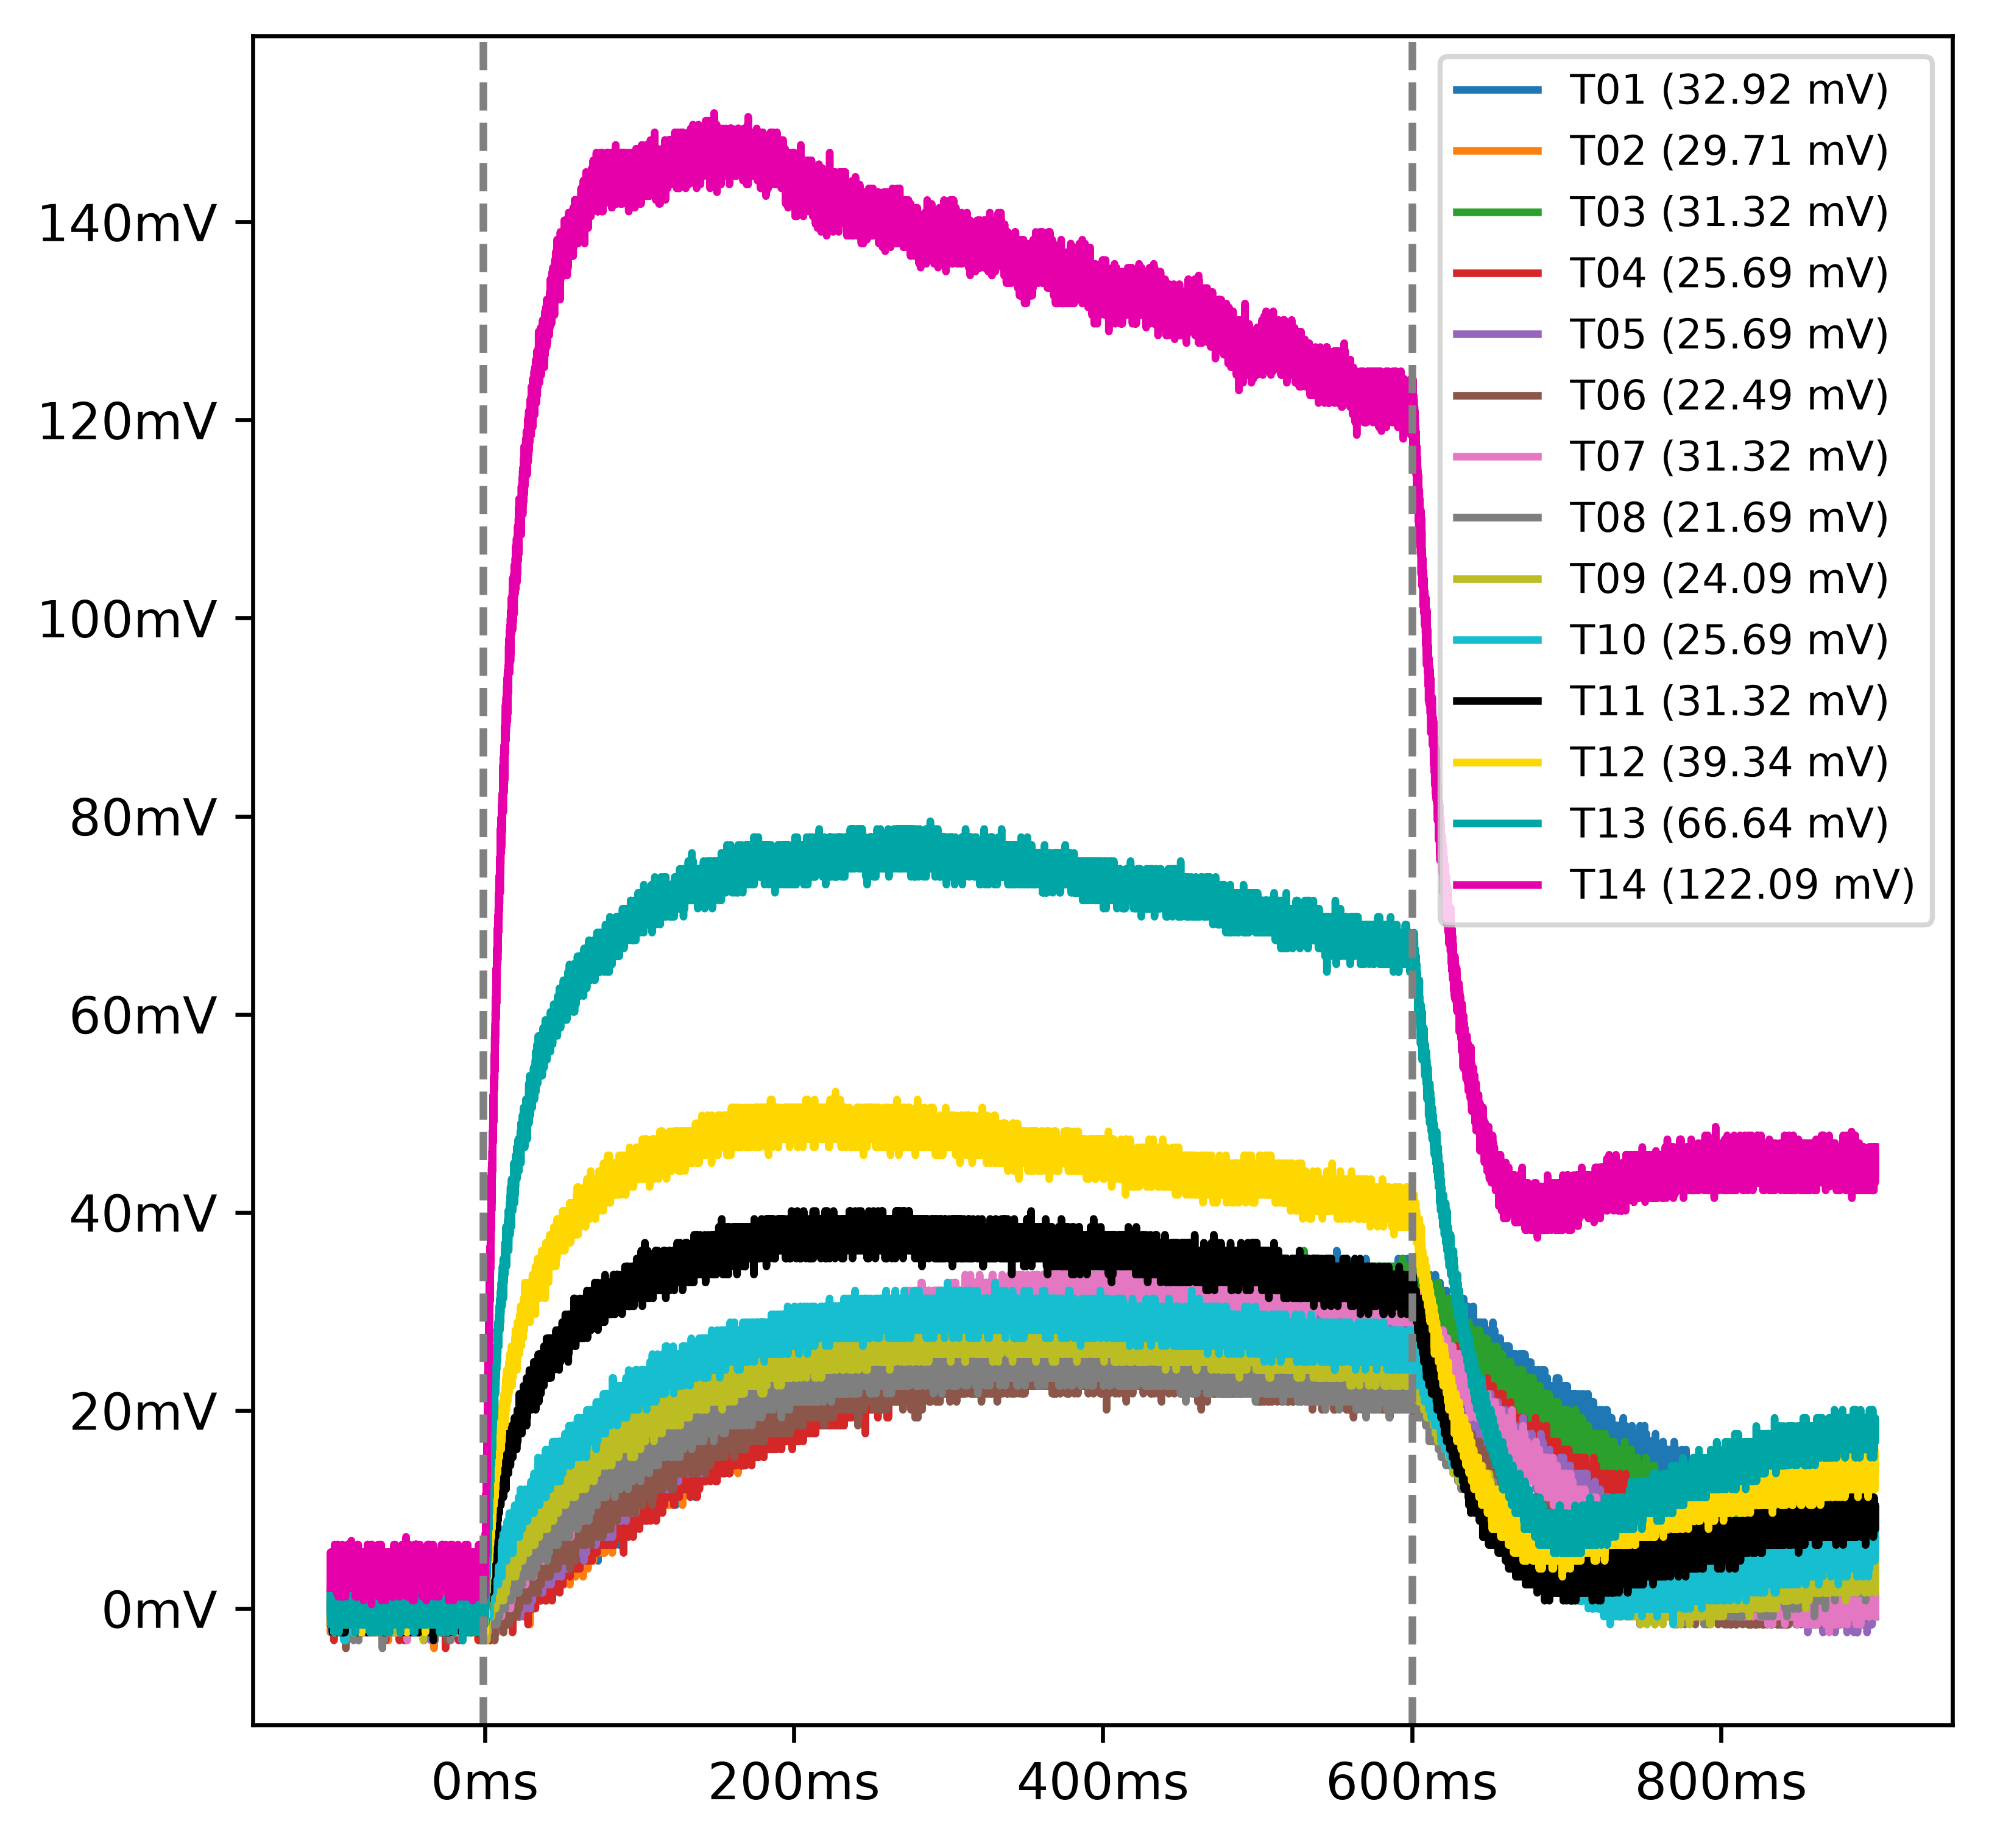

In [73]:
RMS_MEAS_POINT = 0.6  # Fixed constant from initial trigger
RMS_NULL_MEAS_POINT = -0.001  # Point before current starts for null measurement


def get_adc_measurement(
    df: pd.DataFrame, series_name: str, measurement_point: float
) -> float:
    measure_time = (
        df["Time(s)"]
        .iloc[(df["Time(s)"] - measurement_point).abs().argsort()[:1]]
        .values[0]
    )
    measure_value = df[series_name][df["Time(s)"] == measure_time].values[0]
    return measure_value  # type: ignore


def get_max_measurement(df: pd.DataFrame, series_name: str) -> float:
    return df[series_name].max()


def plot_math_output(df: pd.DataFrame, ax: Axes) -> None:
    test = df.attrs["Test"]

    measure_value = get_adc_measurement(df, "Math1", RMS_MEAS_POINT)

    ax.plot(
        df["Time(s)"],
        df["Math1"],
        label=f"T{test} ({measure_value*1000:.2f} mV)",
    )


def plot_math_outputs(dfs: List[pd.DataFrame]) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 6))

    for df in dfs:
        plot_math_output(df, ax)

    ax.axvline(RMS_NULL_MEAS_POINT, color="gray", linestyle="--")
    ax.axvline(RMS_MEAS_POINT, color="gray", linestyle="--")

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax.legend(fontsize=8)

    return fig


plot_math_outputs(scope_dfs)

In [74]:
RMS_OUTPUT_DIR = os.path.join(PLOT_OUTPUT_DIR, "RMS/Transients")
os.makedirs(RMS_OUTPUT_DIR, exist_ok=True)

for i, df in enumerate(scope_dfs):
    fig, ax = plt.subplots(figsize=(6, 6))
    plot_math_output(df, ax)

    ax.axvline(RMS_NULL_MEAS_POINT, color="gray", linestyle="--")
    ax.axvline(RMS_MEAS_POINT, color="gray", linestyle="--")

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax.set_title(f"T{df.attrs['Test']}, C{df.attrs['Battery']}")
    ax.legend(fontsize=8)

    plt.savefig(
        os.path.join(
            RMS_OUTPUT_DIR,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}_math_output.png",
        ),
        bbox_inches="tight",
    )
    plt.close(fig)

In [75]:
RMS_VIN_OUTPUT_DIR = os.path.join(PLOT_OUTPUT_DIR, "RMS/Linearity")
os.makedirs(RMS_VIN_OUTPUT_DIR, exist_ok=True)


def plot_math_output_vs_voltage(df: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 6))

    test = df.attrs["Test"]
    battery = df.attrs["Battery"]

    measure_value = get_adc_measurement(df, "Math1", RMS_MEAS_POINT)
    voltage_value = get_adc_measurement(df, "Channel2", RMS_MEAS_POINT)

    ax.plot(
        df["Time(s)"],
        df["Channel2"],
        color="red",
        label=f"T{test} C{battery} Voltage ({voltage_value:.2f} V)",
    )

    ax.plot(
        df["Time(s)"],
        df["Math1"],
        label=f"T{test} C{battery} ({measure_value*1000:.2f} mV, {voltage_value:.2f} V)",
    )

    # Calculate the RMS value of the channel 2 voltage over the RMS_WINDOW
    voltage_rms = calculate_rms(df["Channel2"], df["Time(s)"], RMS_WINDOW)
    ax.axhline(voltage_rms, color="gray", linestyle="--")
    ax.annotate(
        f"{1000*voltage_rms:.2f} mV RMS",
        xy=(0.5, voltage_rms),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

    return fig


for i, df in enumerate(scope_dfs):
    fig = plot_math_output_vs_voltage(df)

    fig.savefig(
        os.path.join(
            RMS_VIN_OUTPUT_DIR,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}_math_output_vs_voltage.png",
        ),
        bbox_inches="tight",
    )

ADC vs Oscilloscope RMS regression: b = 0.02


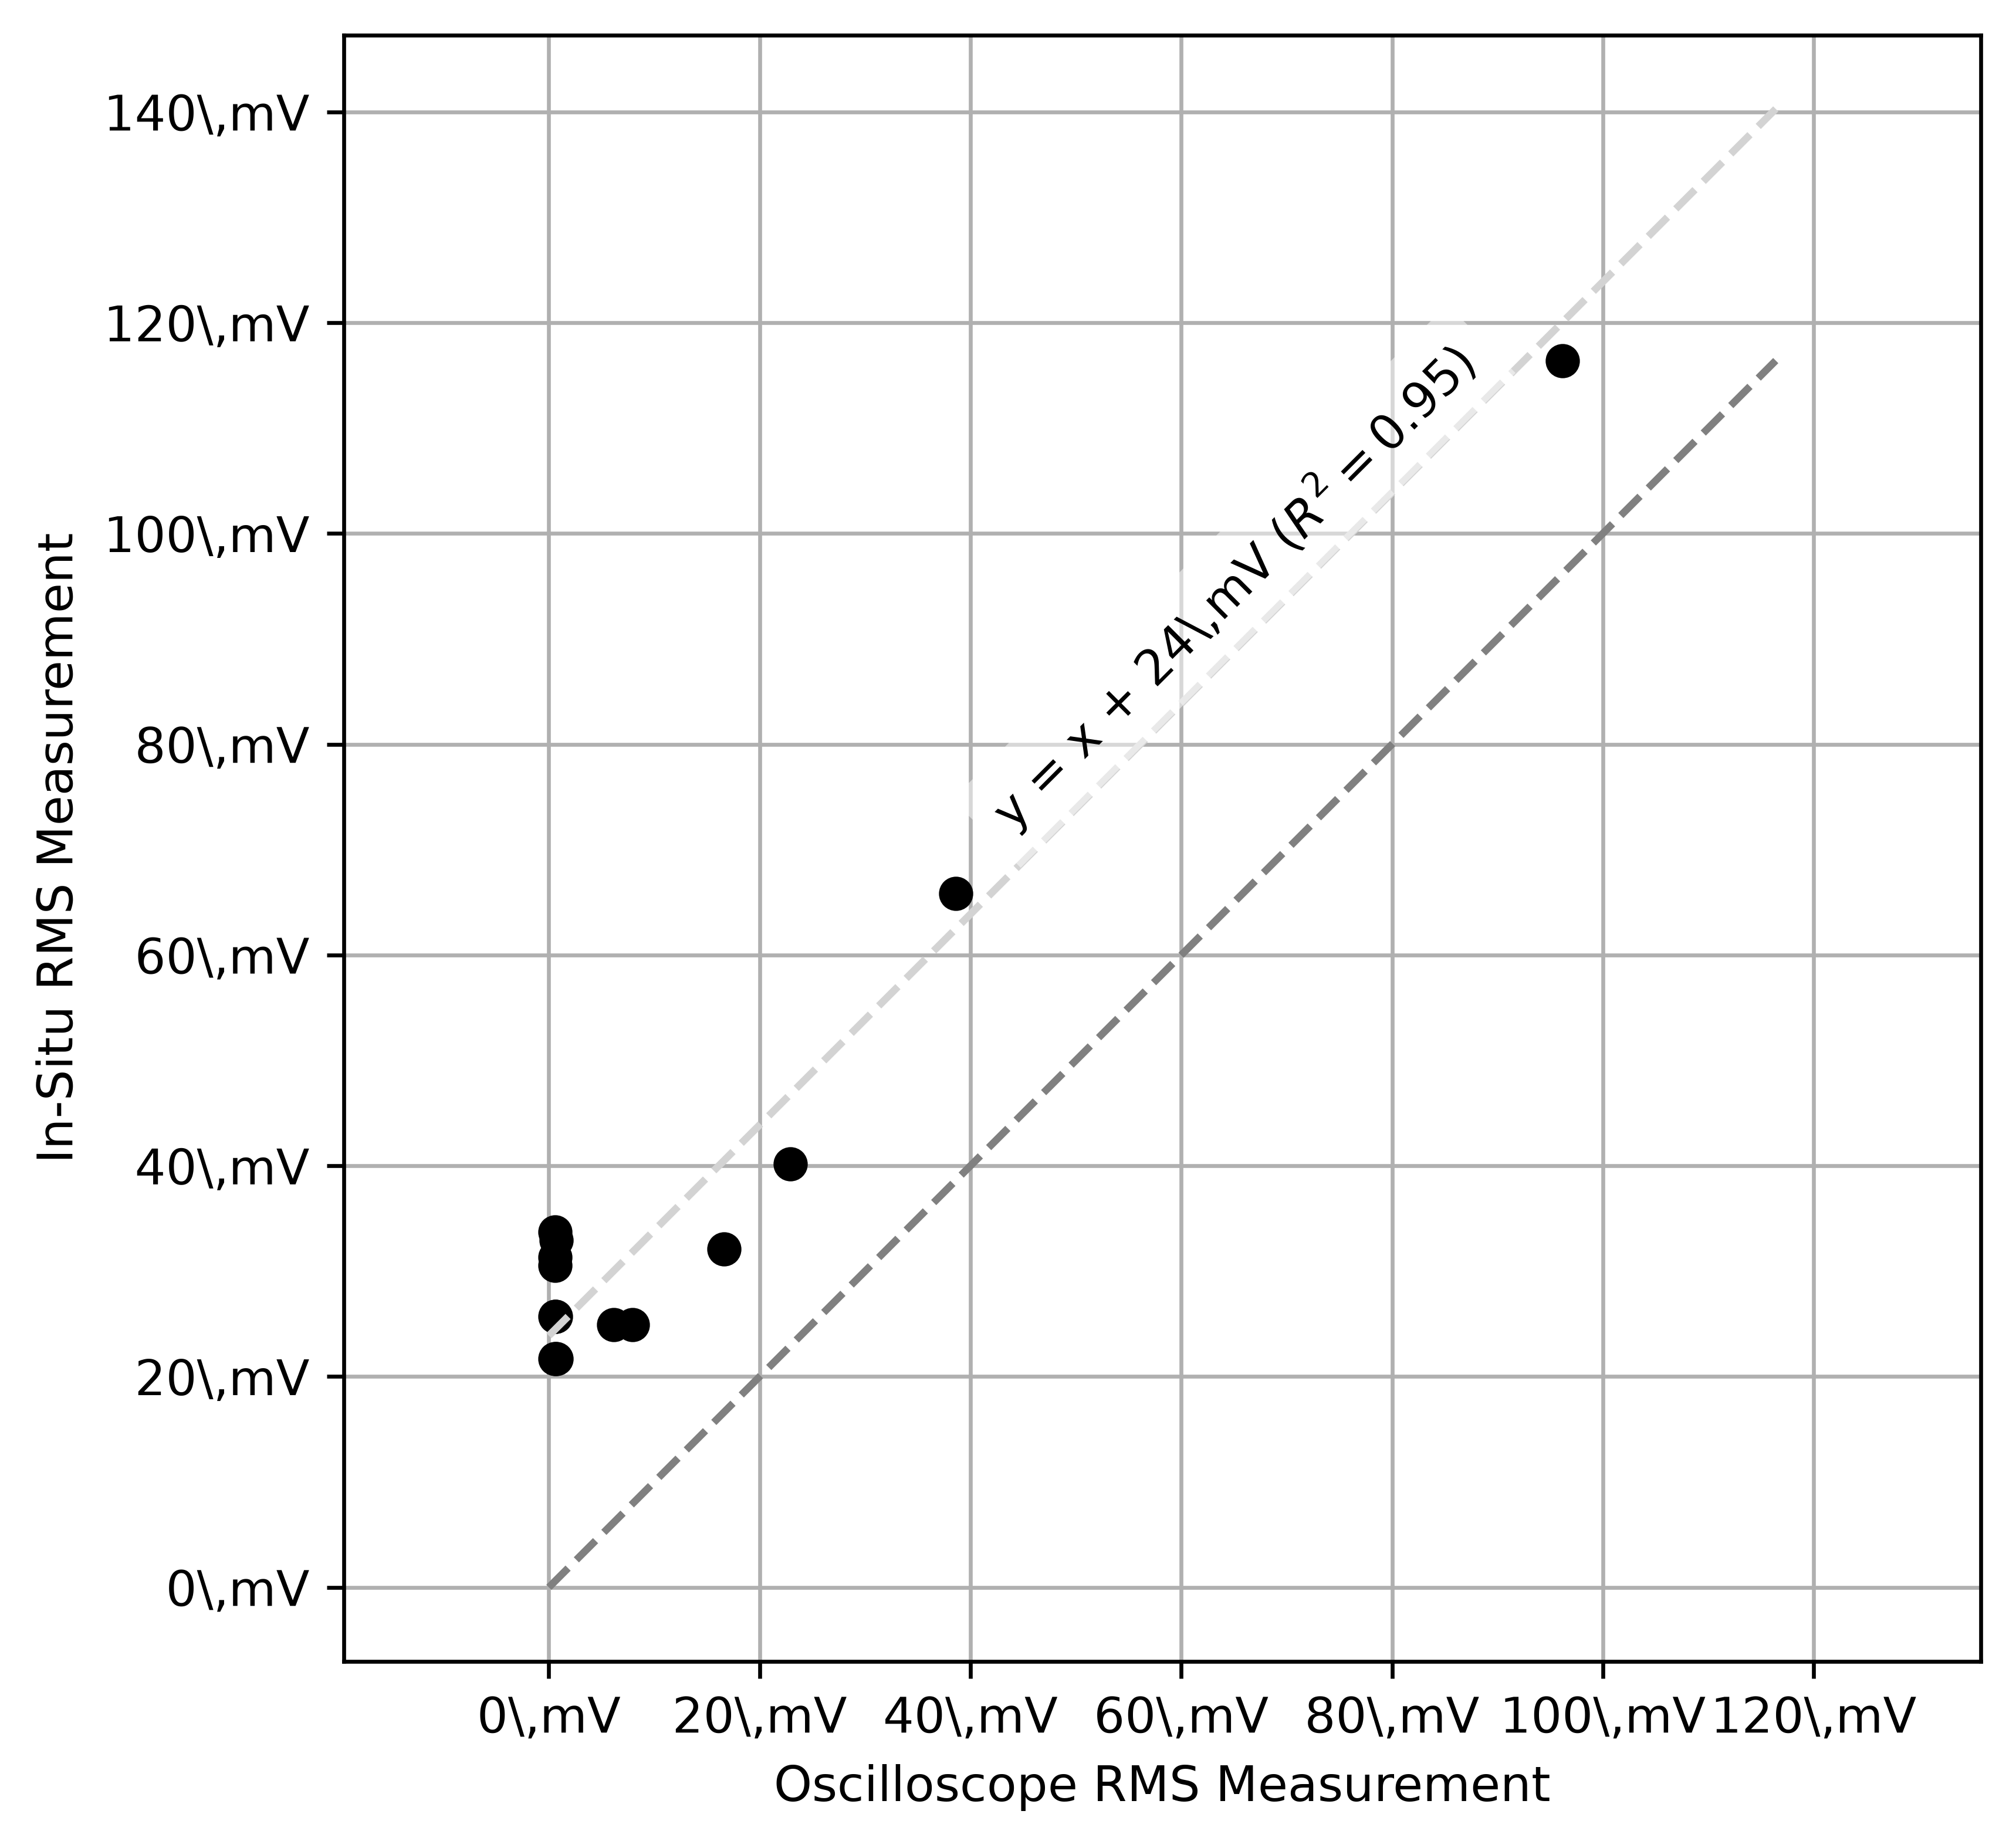

In [76]:
adc_rms_measured_values = [
    (
        get_adc_measurement(df, "Math1", RMS_MEAS_POINT)
        - get_adc_measurement(df, "Math1", RMS_NULL_MEAS_POINT)
    )
    for df in scope_dfs
]
osc_rms_measured_values = voltage_rms_values


def plot_adc_vs_oscilloscope_rms(
    adc_values: List[float], osc_values: List[float]
) -> Tuple[Figure, float]:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(
        osc_values,
        # adc_values / np.sqrt(2),
        adc_values,
        marker="o",
        linestyle="",
        color="black",
    )

    # Plot regression line
    popt, _ = scipy.optimize.curve_fit(
        lambda x, b: 1 * x + b, osc_values, adc_values, p0=(0.0)
    )
    print(f"ADC vs Oscilloscope RMS regression: b = {popt[0]:.2f}")

    b = popt[0]

    r2 = np.corrcoef(osc_values, adc_values)[0, 1] ** 2

    x_fit = np.linspace(0, max(max(adc_values), max(osc_values)), 100)
    y_fit = x_fit + b
    ax.plot(x_fit, y_fit, color="lightgray", linestyle="--", label=f"y = x + {b:.2f}")
    ax.text(
        0.065,
        0.095,
        rf"y = x + {1000*b:.0f}\,mV ($R^2 = {r2:.2f}$)",
        rotation=45,
        # transform=ax.transAxes,
        fontsize=10,
        verticalalignment="center",
        horizontalalignment="center",
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )

    ax.plot(
        [0, max(max(adc_values), max(osc_values))],
        [0, max(max(osc_values), max(adc_values))],
        color="gray",
        linestyle="--",
    )

    ax.set_ylabel("In-Situ RMS Measurement")
    ax.set_xlabel("Oscilloscope RMS Measurement")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}\,mV"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}\,mV"))

    ax.set_aspect("equal", adjustable="datalim")

    ax.grid(True)
    return fig, b


_, injected_offset = plot_adc_vs_oscilloscope_rms(
    adc_rms_measured_values, osc_rms_measured_values
)
_

In [77]:
# Print ADC vs Oscilloscope RMS values
print(
    tabulate(
        [
            [
                df.attrs["Test"],
                df.attrs["Battery"],
                f"{1000*adc:.2f} mV",
                f"{1000*osc:.2f} mV",
            ]
            for df, adc, osc in zip(
                scope_dfs, adc_rms_measured_values, osc_rms_measured_values
            )
        ],
        headers=["Test", "Battery", "ADC RMS", "Oscilloscope RMS"],
    )
)

  Test    Battery  ADC RMS    Oscilloscope RMS
------  ---------  ---------  ------------------
    01         01  33.73 mV   0.60 mV
    02         02  30.53 mV   0.57 mV
    03         03  31.33 mV   0.59 mV
    04         04  25.70 mV   0.59 mV
    05         05  25.70 mV   0.62 mV
    06         06  21.70 mV   0.60 mV
    07         07  32.93 mV   0.70 mV
    08         08  21.70 mV   0.69 mV
    09         09  24.90 mV   6.13 mV
    10         10  24.90 mV   7.93 mV
    11         11  32.13 mV   16.63 mV
    12         12  40.16 mV   22.93 mV
    13         13  65.86 mV   38.61 mV
    14         14  116.41 mV  96.16 mV


In [78]:
def plot_voltage_current(df: pd.DataFrame) -> Figure:
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(2, 2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0, 0])
    ax3 = fig.add_subplot(gs[0, 1], sharey=ax1)
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
    ax4 = fig.add_subplot(gs[1, 1], sharex=ax3, sharey=ax2)

    axes = [ax1, ax2, ax3, ax4]

    TIME = df["Time(s)"]
    VOLTAGE = df["Channel2"]
    CURRENT = iamp_voltage_to_current(diff_n=df["Channel1"], DIFF_P=CURRENT_DIFF_P)

    ax1.plot(
        TIME,
        CURRENT,
        label="Current",
        color="blue",
    )
    ax2.plot(
        TIME,
        VOLTAGE,
        label="Voltage",
        color="red",
    )

    ZOOM_PERIOD = (-0.001, 0.005)
    ZOOM_MASK = (TIME >= ZOOM_PERIOD[0]) & (TIME <= ZOOM_PERIOD[1])
    ax3.plot(
        TIME[ZOOM_MASK],
        CURRENT[ZOOM_MASK],
        label="Current",
        color="blue",
    )
    ax4.plot(
        TIME[ZOOM_MASK],
        VOLTAGE[ZOOM_MASK],
        label="Voltage",
        color="red",
    )
    for ax in [ax1, ax2, ax3, ax4]:
        for lim in ZOOM_PERIOD:
            ax.axvline(lim, color="gray", linestyle="--")

    phase_diff = calculate_phase_difference(df, PHASE_WINDOW)
    ax4.text(
        0.05,
        0.1,
        rf"$\angle$ {phase_diff:.2f}°",
        transform=ax4.transAxes,
        ha="left",
        va="center",
    )

    ax1.set_title("Load Current")
    ax2.set_title("Battery Terminal Voltage (AC Coupled)")
    ax3.set_title("Zoomed Current")
    ax4.set_title("Zoomed Voltage")

    ax1.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.1f}mA"))
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax3.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.1f}mA"))
    ax4.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))

    ax2.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}s"))
    ax4.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))

    return fig


VI_OUTPUT_DIR = os.path.join(PLOT_OUTPUT_DIR, "VI")
os.makedirs(VI_OUTPUT_DIR, exist_ok=True)


def save_voltage_current_plot(df: pd.DataFrame, dir: str) -> None:
    fig = plot_voltage_current(df)
    fig.savefig(
        os.path.join(
            dir,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}.png",
        ),
        bbox_inches="tight",
    )
    plt.close(fig)


with ThreadPoolExecutor() as executor:
    for df in scope_dfs:
        executor.submit(
            save_voltage_current_plot,
            df,
            VI_OUTPUT_DIR,
        )

/var/folders/3f/ct0r54cd0497vnq7h8jk96q40000gp/T/ipykernel_42344/2413367302.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(14, 8))


In [79]:
from Impedance import plot_impedance_vs_freezing, impedances, freezing_extents, OUTLIERS  # type: ignore

freezing_vs_impedance_fig = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    include_non_freezing=False,
    filter_outliers=OUTLIERS,
    annotate=False,
)

In [80]:
def add_scope_impedance_to_plot(
    fig: Figure,
    scope_impedances: List[float],
    scope_freezing_extents: List[float],
) -> Figure:
    scope_impedances = [
        z for z, f in zip(scope_impedances, scope_freezing_extents) if f > 0
    ]
    scope_freezing_extents = [f for f in scope_freezing_extents if f > 0]

    ax = fig.axes[0]
    ax.plot(
        scope_freezing_extents,
        scope_impedances,
        marker="x",
        color="black",
        label="Scope Measurements",
        linestyle="",
    )

    # Fit data to Archie's Law: Z = Z0 * (1 - F)^(-n)
    popt, _ = scipy.optimize.curve_fit(
        lambda F, Z0, n: Z0 * (1 - F) ** (-n),
        scope_freezing_extents,
        scope_impedances,
        p0=(1.0, 1.0),
    )
    print(f"Archie's Law parameters (Scope): Z0 = {popt[0]:.2f}, n = {popt[1]:.2f}")
    ax.plot(
        np.linspace(min(scope_freezing_extents), max(scope_freezing_extents), 100),
        popt[0]
        * (
            1
            - np.linspace(min(scope_freezing_extents), max(scope_freezing_extents), 100)
        )
        ** (-popt[1]),
        color="lightgray",
        linestyle="--",
        label=rf"$R = R_0(1 - F)^{{-{popt[1]:.2f}}}$ (Scope)",
    )

    # turn off ax[1] legend
    fig.axes[0].legend().set_visible(False)

    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", color="black", linestyle="", label="Measured"),
            Line2D(
                [0], [0], marker="x", color="black", linestyle="", label="Oscilloscope"
            ),
            Line2D(
                [0],
                [0],
                marker="^",
                markeredgecolor="black",
                markerfacecolor="white",
                linestyle="",
                label="Crouch \& Reitz 1990",
            ),
            Line2D(
                [0],
                [0],
                color="lightgray",
                linestyle="--",
                label=rf"$R = R_0(1 - F)^{{-{popt[1]:.2f}}}$ (Scope)",
            ),
        ],
        labels=[
            "Measured",
            "Oscilloscope",
            "Crouch \& Reitz 1990",
            rf"$R = R_0(1 - F)^{{-{popt[1]:.2f}}}$",
        ],
        fontsize=12,
        loc="center left",
    )

    return fig

In [81]:
# freezing_vs_impedance_fig_scope = add_scope_impedance_to_plot(
#     freezing_vs_impedance_fig,
#     scope_impedance_values,
#     scope_freezing_extent_values,
# )
# freezing_vs_impedance_fig_scope

In [82]:
from Impedance import add_saturation_to_impedance_plot, saturation_data  # type: ignore

REFERENCE_CELL_RESISTANCE = (
    0.039  # Ohm, sample resistance at zero thickness, Crough and Reitz, 1990
)


# freezing_vs_impedance_fig_scope_sat = add_saturation_to_impedance_plot(
#     freezing_vs_impedance_fig_scope,
#     saturation_data,
#     nominal_saturation=1.0,
# )

# freezing_vs_impedance_fig_scope_sat

## Subplot Comparison

In [83]:
from Impedance import impedance, dataframes, get_vrms, get_vrms_std, get_irms  # type: ignore

In [84]:
impedances_offset_compensated = {}
impedances_not_offset_compensated = {}
for df in dataframes:
    test = df.attrs["test"]
    battery = df.attrs["battery"]
    vrms = get_vrms(df["Vrms"])
    vrms_std = get_vrms_std(df["Vrms"])
    vrms_null = get_vrms(df["VrmsNull"])
    irms = get_irms(df.attrs["header"])

    impedances_offset_compensated[test] = impedance(
        vrms - injected_offset, vrms_null, irms
    )
    impedances_not_offset_compensated[test] = impedance(vrms, vrms_null, irms)

    impedances_std = vrms_std / irms

    print(
        f"Test: {test}, Battery: {battery}, Vrms: {1000*vrms:.3f} mV, VrmsNull: {1000*vrms_null:.3f} mV, Irms: {1000*irms:.3f} mA, Impedance: {impedances[test]:.6f} ± {impedances_std:.6f} Ω, Error: ±{100*impedances_std/impedances[test]:.1f} %"
    )

Test: T01, Battery: C01, Vrms: 34.391 mV, VrmsNull: 2.164 mV, Irms: 106.066 mA, Impedance: 0.303839 ± 0.000480 Ω, Error: ±0.2 %
Test: T02, Battery: C02, Vrms: 31.371 mV, VrmsNull: 2.179 mV, Irms: 106.066 mA, Impedance: 0.275225 ± 0.002343 Ω, Error: ±0.9 %
Test: T03, Battery: C03, Vrms: 34.438 mV, VrmsNull: 2.163 mV, Irms: 106.066 mA, Impedance: 0.304288 ± 0.001107 Ω, Error: ±0.4 %
Test: T04, Battery: C04, Vrms: 29.949 mV, VrmsNull: 2.174 mV, Irms: 106.066 mA, Impedance: 0.261865 ± 0.000304 Ω, Error: ±0.1 %
Test: T05, Battery: C05, Vrms: 30.191 mV, VrmsNull: 2.188 mV, Irms: 106.066 mA, Impedance: 0.264021 ± 0.000481 Ω, Error: ±0.2 %
Test: T06, Battery: C06, Vrms: 25.251 mV, VrmsNull: 2.164 mV, Irms: 106.066 mA, Impedance: 0.217669 ± 0.000764 Ω, Error: ±0.4 %
Test: T07, Battery: C07, Vrms: 33.803 mV, VrmsNull: 2.167 mV, Irms: 106.066 mA, Impedance: 0.298264 ± 0.001182 Ω, Error: ±0.4 %
Test: T08, Battery: C08, Vrms: 25.107 mV, VrmsNull: 2.188 mV, Irms: 106.066 mA, Impedance: 0.216082 ± 0.

/var/folders/3f/ct0r54cd0497vnq7h8jk96q40000gp/T/ipykernel_42344/3702795257.py:8: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(8, 6))


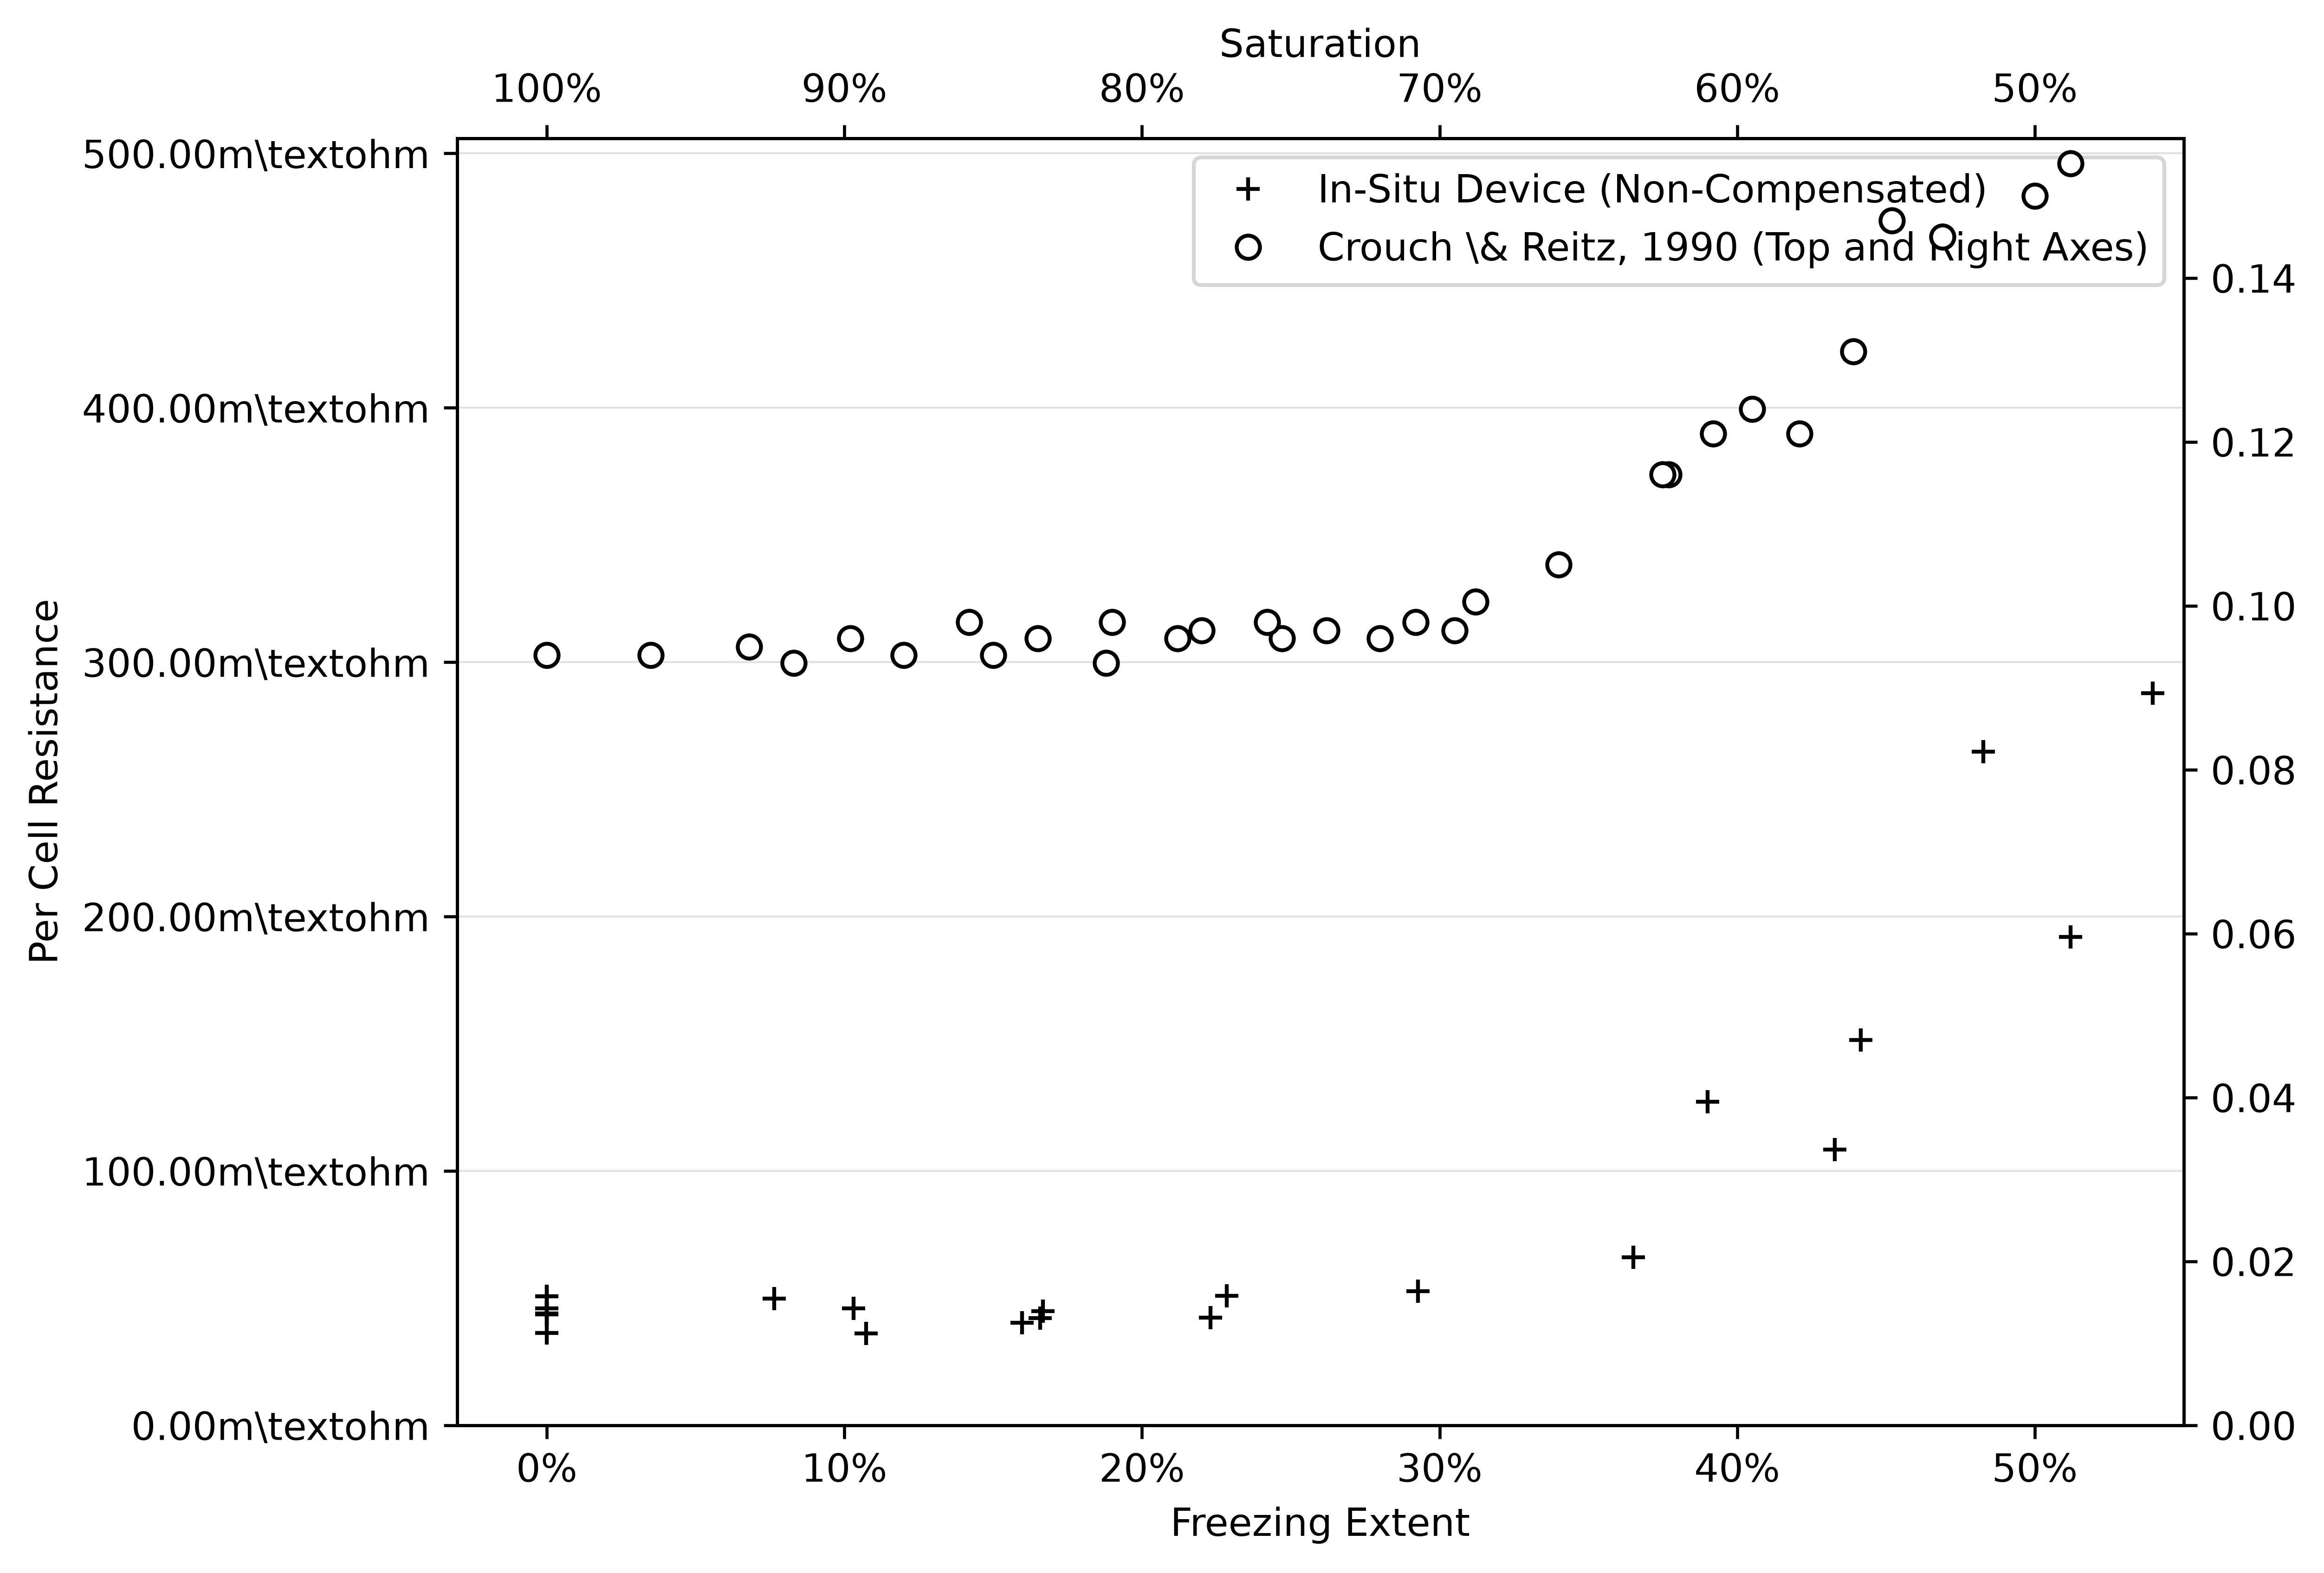

In [85]:
def plot_non_compensated_vs_saturation(
    impedances_not_offset_compensated: Dict[str, float],
    freezing_extents: dict,
    scope_impedance_values: List[float],
    scope_freezing_extent_values: List[float],
    saturation_data: pd.DataFrame,
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))
    ax_sat = ax.twinx()

    # Plot non-compensated impedance vs saturation
    valid_tests = sorted(
        [f for f in impedances_not_offset_compensated.keys() if f not in OUTLIERS]
    )
    z_non_comp = [impedances_not_offset_compensated[f] for f in valid_tests]
    f_ext = [freezing_extents.get(f, 0.0) for f in valid_tests]

    ax.plot(
        f_ext,
        np.asarray(z_non_comp, dtype=float) / 6,
        marker="+",
        color="black",
        linestyle="",
        label="In-Situ Device (Non-Compensated)",
    )

    # ax.plot(
    #     scope_freezing_extent_values,
    #     np.asarray(scope_impedance_values, dtype=float) / 6,
    #     marker="x",
    #     color="black",
    #     linestyle="",
    #     label="Oscilloscope DSP",
    # )

    ax_sat.plot(
        1 - saturation_data["Saturation"] / 100,
        saturation_data["Cell Resistance"],
        marker="o",
        markeredgecolor="black",
        markerfacecolor="white",
        linestyle="",
        color="black",
        label=r"Crouch \& Reitz, 1990",
    )

    # Dummy plot for legend labels
    ax.plot(
        [],
        [],
        marker="o",
        color="black",
        linestyle="",
        label=r"Crouch \& Reitz, 1990 (Top and Right Axes)",
        markeredgecolor="black",
        markerfacecolor="white",
    )

    ax.set_xlabel("Freezing Extent")
    ax.set_ylabel("Per Cell Resistance")
    ax.grid(color="lightgray", linewidth=0.5, alpha=0.7, axis="y")
    ax.legend()
    ax.set_ylim(bottom=0)
    ax.set_xlim(right=0.55)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: rf"{1000*y:.2f}m\textohm"))

    ax_sat_top = ax_sat.secondary_xaxis(
        "top",
        functions=(lambda x: 1 - x, lambda x: 1 - x),
    )
    ax_sat_top.set_xlabel("Saturation")
    ax_sat_top.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax_sat.set_ylim(bottom=0)
    ax_sat.set_xlim(right=0.55)

    return fig


plot_non_compensated_vs_saturation(
    impedances_not_offset_compensated,
    freezing_extents,
    scope_impedance_values,
    scope_freezing_extent_values,
    saturation_data,
)

In [ ]:
def fit_archies_law(
    x: np.ndarray,
    y: np.ndarray,
) -> Tuple[float, float, float]:
    """
    Fit Archie's Law to the given data.

    Parameters:
        x (np.ndarray): The independent variable (freezing extent).
        y (np.ndarray): The dependent variable (impedance).

    Returns:
        Tuple[float, float, float]: The fitted parameters (Z0, n, R²) of Archie's Law.
    """
    popt, _ = scipy.optimize.curve_fit(
        lambda F, Z0, n: Z0 * ((1 - F) ** (-n)),
        x,
        y,
        p0=(1.0, 1.0),
    )
    r2 = np.corrcoef(y, popt[0] * (1 - x) ** (-popt[1]))[0, 1] ** 2
    # print(f"Archie's Law fit: Z0 = {popt[0]:.2f}, n = {popt[1]:.2f}, R² = {r2:.4f}")
    return popt[0], popt[1], r2  # Z0, n, R²


def get_linear_correlation(items):
    p = Polynomial.fit([x for x, _ in items], [y for _, y in items], deg=1)
    monomial = p.convert()
    a, b = monomial.coef[1], monomial.coef[0]
    r2 = np.corrcoef([y for _, y in items], [p(x) for x, _ in items])[0, 1] ** 2

    return p, a, b, r2

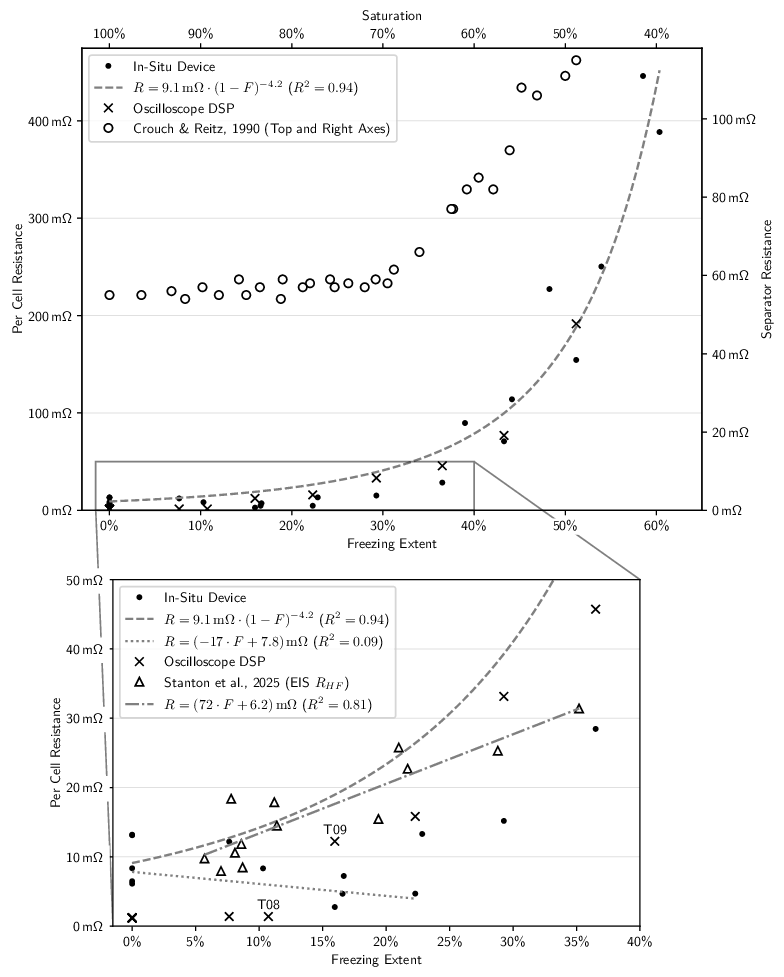

In [96]:
from matplotlib import patches


def subplot_impedance_scope_saturation(
    impedances: dict,
    freezing_extents: dict,
    scope_impedances: List[float],
    scope_freezing_extents: List[float],
    saturation_data: Dict[str, Any],
    eis_data: pd.DataFrame,
) -> Figure:
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(8, 6),
        # Increase spacing between subplots
    )

    ax0 = ax
    ax1 = ax0.twinx()
    ax_zoom = ax0.inset_axes([0.05, -0.9, 0.85, 0.75])  # type: ignore

    valid_tests = sorted([f for f in impedances if f not in OUTLIERS])
    z = [impedances[f] for f in valid_tests]
    fe = [freezing_extents.get(f, 0.0) for f in valid_tests]
    for axis in [ax0, ax_zoom]:
        axis.plot(
            fe,
            np.asarray(z, dtype=float) / 6.0,  # Per cell
            marker=".",
            color="black",
            label="In-Situ Device",
            linestyle="",
        )

    # Plot archie's Law fit for the in-situ device data
    p, n, r2 = fit_archies_law(np.array(fe), np.array(z) / 6.0)
    x_linspace = np.linspace(min(fe), max(fe), 100)
    for axis in [ax0, ax_zoom]:
        axis.plot(
            x_linspace,
            [p * (1 - F) ** (-n) for F in x_linspace],
            color="grey",
            linestyle="--",
            label=rf"$R = {1000*p:.1f}\,\mathrm{{m\Omega}} \cdot (1 - F)^{{-{n:.1f}}}$ ($R^2 = {r2:.2f}$)",
        )

    # Fit a linear regression for tests of F < 22.5%
    low_fe_tests = [f for f, f_ext in zip(valid_tests, fe) if f_ext < 0.225]
    low_fe_tests.sort(key=lambda f: freezing_extents.get(f, 0.0))
    low_fe_z = [impedances[f] for f in low_fe_tests]
    low_fe_fe = [freezing_extents.get(f, 0.0) for f in low_fe_tests]
    p_low, a_low, b_low, r2_low = get_linear_correlation(
        list(zip(low_fe_fe, np.asarray(low_fe_z, dtype=float) / 6.0))
    )

    ax_zoom.plot(
        [min(low_fe_fe), max(low_fe_fe)],
        [p_low(x) for x in [min(low_fe_fe), max(low_fe_fe)]],
        color="grey",
        linestyle=":",
        label=rf"$R = ({1000*a_low:.0f} \cdot F {1000*b_low:+.1f})\,\mathrm{{m\Omega}}$ ($R^2 = {r2_low:.2f}$)",
    )

    for axis in [ax0, ax_zoom]:
        axis.plot(
            scope_freezing_extents,
            np.asarray(scope_impedances, dtype=float) / 6.0,  # Per cell
            marker="x",
            color="black",
            label="Oscilloscope DSP",
            linestyle="",
        )

    p1, n1, r2 = fit_archies_law(
        np.array(scope_freezing_extents),
        np.array(scope_impedances) / 6.0,
    )
    x_linspace = np.linspace(
        min(scope_freezing_extents), max(scope_freezing_extents), 100
    )

    fit_label_str = (
        rf"$R = {1000*p1:.1f}\,\mathrm{{m\Omega}}"
        rf" \cdot (1 - F)^{{-{n1:.1f}}}"
        rf"\quad (R^2 = {r2:.2f})$"
    )
    # for axis in [ax0, ax_zoom]:
    #     axis.plot(
    #         x_linspace,
    #         [p1 * (1 - F) ** (-n1) for F in x_linspace],
    #         color="grey",
    #         linestyle=":",
    #         label=fit_label_str,
    #     )

    # Add test markers for Test 8 and 9 oscilloscope measurements
    for test in ["T08", "T09"]:
        fe_test = freezing_extents.get(test, 0.0)
        z_test = scope_impedances[valid_tests.index(test)] / 6.0
        ax_zoom.text(
            fe_test,
            z_test + 0.001,
            test,
            fontsize=10,
            ha="center",
            va="bottom",
        )

    # Plot of EIS results from Stanton et. al. 2025
    for axis in [ax_zoom]:
        axis.plot(
            eis_data["Freezing Extent"],
            eis_data["High Frequency Resistance(mOhm)"]
            / 1000
            / 6.0,  # Convert mOhm to Ohm
            marker="^",
            markeredgecolor="black",
            markerfacecolor="white",
            label=r"Stanton et al., 2025 (EIS $R_{HF}$)",
            linestyle="",
        )

        # Linear regression line for Stanton et al. 2025 data
        p2, a2, b2, r2_2 = get_linear_correlation(
            list(
                zip(
                    eis_data["Freezing Extent"],
                    eis_data["High Frequency Resistance(mOhm)"] / 1000 / 6.0,
                )
            )
        )
        x_lims_eis = [
            min(eis_data["Freezing Extent"]),
            max(eis_data["Freezing Extent"]),
        ]

        axis.plot(
            x_lims_eis,
            [p2(x) for x in x_lims_eis],
            color="grey",
            linestyle="-.",
            label=rf"$R = ({1000*a2:.0f} \cdot F {1000*b2:+.1f})\,\mathrm{{m\Omega}}$ ($R^2 = {r2_2:.2f}$)",
        )

    ax1.plot(
        1 - (saturation_data["Saturation"] / 100),
        saturation_data["Cell Resistance"] - REFERENCE_CELL_RESISTANCE,
        marker="o",
        markeredgecolor="black",
        markerfacecolor="white",
        label=r"Crouch \& Reitz, 1990",
        linestyle="",
    )

    # Add the label to ax0 legend using a dummy line
    ax0.plot(
        [],
        [],
        color="white",
        marker="o",
        markeredgecolor="black",
        markerfacecolor="white",
        linestyle="",
        label=rf"Crouch \& Reitz, 1990 (Top and Right Axes)",
    )
    ax0_top = ax0.secondary_xaxis(
        "top",
        functions=(
            lambda x: 1 - x,
            lambda x: 1 - x,
        ),
    )
    ax0_top.set_xlabel("Saturation")
    ax0_top.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

    ax0.set_xlim(right=0.65)
    ax0.set_xlabel("Freezing Extent")
    ax0.set_ylabel("Per Cell Resistance")
    ax0.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax0.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: rf"{1000*y:.0f}\,m\textohm")
    )
    ax0.set_ylim(bottom=0)
    ax0.legend()
    ax0.grid(color="lightgray", linewidth=0.5, alpha=0.7, axis="y")

    ax1.set_xlabel("Saturation")
    ax1.set_ylabel("Separator Resistance")
    ax1.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: rf"{1000*y:.0f}\,m\textohm")
    )

    ax1.set_ylim(bottom=0)

    ax_zoom.set_xlim(ax0.get_xlim()[0] / 2, 0.4)
    ax_zoom.set_ylim(0, 0.05)

    ax_zoom.set_xlabel("Freezing Extent")
    ax_zoom.set_ylabel("Per Cell Resistance")
    ax_zoom.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax_zoom.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: rf"{1000*y:.0f}\,m\textohm")
    )
    # Place white background behind the yaxis tick markers to mask the indicator lines
    ax0.indicate_inset_zoom(ax_zoom, edgecolor="black", alpha=0.5)
    plt.setp(
        ax_zoom.get_yticklabels(),
        backgroundcolor="white",
    )
    plt.setp(
        ax0.get_xticklabels(),
        backgroundcolor="white",
    )
    ax0.xaxis.set_zorder(5)
    for label in ax0.get_xticklabels():
        label.set_backgroundcolor("white")
        label.set_bbox(
            dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.1")
        )

    ax_zoom.grid(color="lightgray", linewidth=0.5, alpha=0.7, axis="y")
    ax_zoom.legend(loc="upper left")

    return fig


subplot_impedance_scope_saturation(
    impedances=impedances_offset_compensated,
    freezing_extents=freezing_extents,
    scope_impedances=scope_impedance_values,
    scope_freezing_extents=scope_freezing_extent_values,
    saturation_data=saturation_data,
    eis_data=eis_df,
)

## PGF Export

In [97]:
import matplotlib

matplotlib.use("pgf")

plt.rcParams.update(matplotlib.rcParamsDefault)
plt.rcParams.update(
    {
        "pgf.texsystem": "lualatex",
        "text.usetex": True,
        "pgf.rcfonts": False,
        # "axes.prop_cycle": cycler(color=colorBlindColors),
    }
)

PGF_OUTPUT_PATH = "../Plots/Latex"
os.makedirs(PGF_OUTPUT_PATH, exist_ok=True)

plt.rcParams["axes.prop_cycle"] = cycler(
    "color", plt.rcParams["axes.prop_cycle"].by_key()["color"] + additional_colors
)

In [98]:
# freezing_vs_impedance_fig_pgf = plot_impedance_vs_freezing(
#     impedances,
#     freezing_extents,
#     include_non_freezing=False,
#     filter_outliers=OUTLIERS,
#     annotate=False,
# )

# freezing_vs_impedance_scope_fig_pgf = add_scope_impedance_to_plot(
#     freezing_vs_impedance_fig_pgf,
#     scope_impedance_values,
#     scope_freezing_extent_values,
# )

# freezing_vs_impedance_scope_fig_pgf.axes[0].set_title("")

# freezing_vs_impedance_scope_fig_pgf.savefig(
#     os.path.join(PGF_OUTPUT_PATH, "impedance_vs_freezing_scope.pgf"),
#     bbox_inches="tight",
# )

In [99]:
freezing_vs_impedance_scope_sat_fig_pgf = subplot_impedance_scope_saturation(
    impedances=impedances_offset_compensated,
    freezing_extents=freezing_extents,
    scope_impedances=scope_impedance_values,
    scope_freezing_extents=scope_freezing_extent_values,
    saturation_data=saturation_data,
    eis_data=eis_df,
)

freezing_vs_impedance_scope_sat_fig_pgf.savefig(
    os.path.join(PGF_OUTPUT_PATH, "impedance_vs_freezing_scope_saturation.pgf"),
    bbox_inches="tight",
)

In [100]:
for df in scope_dfs:
    fig = plot_voltage_current(df)

    for ax in fig.get_axes():
        for line in ax.get_lines():
            line.set_color("black")

    fig.savefig(
        os.path.join(
            PGF_OUTPUT_PATH,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}.pgf",
        ),
        bbox_inches="tight",
    )

    if df.attrs["Test"] == "08":
        fig.axes[3].set_ylim(-0.2, 0.1)

        fig.savefig(
            os.path.join(
                PGF_OUTPUT_PATH,
                f"T{df.attrs['Test']}_C{df.attrs['Battery']}_Scaled.pgf",
            ),
            bbox_inches="tight",
        )

    plt.close(fig)

In [101]:
rms_fig = plot_math_outputs(scope_dfs)

rms_fig.savefig(
    os.path.join(
        PGF_OUTPUT_PATH,
        f"RMS.pgf",
    ),
    bbox_inches="tight",
)

In [102]:
rms_linear_fig, _ = plot_adc_vs_oscilloscope_rms(
    adc_rms_measured_values, osc_rms_measured_values
)

rms_linear_fig.savefig(
    os.path.join(
        PGF_OUTPUT_PATH,
        f"RMS_Linear.pgf",
    ),
    bbox_inches="tight",
)

ADC vs Oscilloscope RMS regression: b = 0.02


In [103]:
uncompensated_vs_saturation_fig = plot_non_compensated_vs_saturation(
    impedances_not_offset_compensated,
    freezing_extents,
    scope_impedance_values,
    scope_freezing_extent_values,
    saturation_data,
)

uncompensated_vs_saturation_fig.savefig(
    os.path.join(
        PGF_OUTPUT_PATH,
        f"Uncompensated_vs_Saturation.pgf",
    ),
    bbox_inches="tight",
)